# Яркость адаптации сетчатки La

### Фиксация параметров из предыдущих исследований:
- **Из исследования 1**:
  - Модель внимания: UNISAL (оригинальное разрешение)
  - Порог внимания: топ-5%
  - DBSCAN: eps = 4.0 px, min_samples = 5
  - Центры кластеров: геометрические
- **Из исследования 2**:
  - Все три радиуса (R_gyr, D_disk, R_max) оставлены для сравнения их влияния на поиск La

### Сетка расчета La (12 конфигураций):
- 3 варианта радиуса: R_gyr, D_disk, R_max
- 2 размера стимула: угловой размер пикселя phi_px vs угловой размер объекта phi_d
- 2 способа взвешивания кластеров: поровну (1/K) vs по весам внимания (w_k)

In [9]:
import sys
import math
from pathlib import Path
import cv2
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import DBSCAN
from IPython.display import display

sys.path.append("..")

from src.paths import BASE_DIR
from src.geometry import ViewingGeometry
from src.foveation.retina import load_retina_biology
from src.utils.converter import ImageConverter
from src.foveation.foveation import extract_fixation_luminances
from src.keypoints.types import ClusterInfo
from src.keypoints.saliency.unisal_model import load_unisal_model, predict_unisal_attention
from src.utils.jnd import FoveatedJND

plt.rcParams['font.size'] = 11

geometry = ViewingGeometry(view_dist_mm=600.0, l_min=0.1, l_max=300.0)
retina = load_retina_biology()
converter = ImageConverter(L_MIN=geometry.l_min, L_MAX=geometry.l_max)

m_unisal = load_unisal_model(device="cpu")

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png"}
EXAMPLE_IMAGES = sorted([
    p for p in (BASE_DIR / "examples").iterdir()
    if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
])

## Графики функций потерь и расчет La

In [10]:
def run_experiment_4(
    img_path_input,
    top_pct: float = 5.0,
    eps: float = 4.0,
    min_samples: int = 10
):
    img_path = Path(img_path_input)
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        print(f"Ошибка загрузки файла: {img_path}")
        return
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    
    lum_map = converter.RGB_to_xyzL(img_rgb)[..., 3]
    mean_frame_lum = float(np.mean(lum_map))
    median_frame_lum = float(np.median(lum_map))
    
    print(f"Изображение: {img_path.name} | Разрешение: {w}x{h} px")
    print(f"Средняя яркость кадра: {mean_frame_lum:.2f} кд/м² | Медианная: {median_frame_lum:.2f} кд/м²\n")
    
    heat_unisal_orig = predict_unisal_attention(img_rgb, m_unisal, resize=False)
    q_th = float(np.percentile(heat_unisal_orig, 100 - top_pct))
    ys, xs = np.where(heat_unisal_orig >= q_th)
    
    if len(xs) == 0:
        print("Кластеры не найдены.\n")
        return
        
    points_full = np.column_stack([xs, ys])
    weights_full = heat_unisal_orig[ys, xs]
    
    stride = max(1, int(np.ceil(len(xs) / 20000)))
    points = points_full[::stride]
    weights = weights_full[::stride]
    eff_min_samples = max(5, int(min_samples / stride))
    
    db = DBSCAN(eps=eps, min_samples=eff_min_samples).fit(points)
    labels = db.labels_
    unique_labels = [k for k in sorted(list(set(labels))) if k != -1]
    
    if not unique_labels:
        print("Значимых кластеров не выделено.\n")
        return
        
    rad_per_px = geometry.rad_per_px(w)
    clusters = []
    r_gyrs = []
    r_disks = []
    r_maxs = []
    
    for k in unique_labels:
        mask = (labels == k)
        c_pts = points[mask]
        c_w = weights[mask]
        n_pts = len(c_pts) * stride
        
        cx = float(np.mean(c_pts[:, 0]))
        cy = float(np.mean(c_pts[:, 1]))
        
        diff = c_pts - np.array([cx, cy])
        dists = np.sqrt(np.sum(diff ** 2, axis=1))
        
        r_gyr = float(np.sqrt(np.mean(dists ** 2)))
        d_disk = float(math.sqrt(n_pts / math.pi))
        r_disk = d_disk / 2.0
        r_max = float(np.max(dists))
        total_w = float(np.sum(c_w)) * stride
        
        clusters.append(ClusterInfo(
            center=(cx, cy),
            radius_px=r_gyr,
            angular_size_rad=2.0 * r_gyr * rad_per_px,
            weight=total_w,
            num_pixels=n_pts,
            points=c_pts
        ))
        r_gyrs.append(r_gyr)
        r_disks.append(r_disk)
        r_maxs.append(r_max)
        
    order = np.argsort([-c.weight for c in clusters])
    clusters = [clusters[i] for i in order]
    r_gyrs = [r_gyrs[i] for i in order]
    r_disks = [r_disks[i] for i in order]
    r_maxs = [r_maxs[i] for i in order]
    
    lums = extract_fixation_luminances(img_rgb, clusters, geometry, retina, converter)
    cl_weights = np.array([c.weight for c in clusters], dtype=np.float64)
    sum_w = float(np.sum(cl_weights))
    w_probs = cl_weights / sum_w if sum_w > 0 else np.full_like(cl_weights, 1.0 / len(clusters))
    u_probs = np.full_like(cl_weights, 1.0 / len(clusters))
    
    cluster_lums_list = [round(float(lum), 2) for lum in lums]
    print(f"Яркости кластеров L_k ({len(clusters)} шт.): {cluster_lums_list} кд/м²\n")
    
    phi_px = rad_per_px
    phi_gyrs = np.array([2.0 * r * rad_per_px for r in r_gyrs], dtype=np.float64)
    phi_disks = np.array([2.0 * r * rad_per_px for r in r_disks], dtype=np.float64)
    phi_maxs = np.array([2.0 * r * rad_per_px for r in r_maxs], dtype=np.float64)
    
    jnd = FoveatedJND(geometry=geometry)
    
    radius_configs = [
        ("Радиус гирации R_gyr", "R_gyr", phi_gyrs),
        ("Эквивалентный диск D_disk", "D_disk", phi_disks),
        ("Радиус до крайней точки R_max", "R_max", phi_maxs)
    ]
    
    detailed_rows = []
    
    la_candidates = np.geomspace(
        max(float(np.min(lums)) * 0.5, geometry.l_min),
        min(float(np.max(lums)) * 2.0, geometry.l_max),
        120
    )
    
    plot_data = []
    
    for r_title, r_code, phi_obj_arr in radius_configs:
        la_px_u = jnd.find_la(lums, weights=None, angular_sizes=phi_px)
        loss_px_u = jnd.loss(la_px_u, lums, u_probs, phi_d=phi_px)
        curve_px_u = [jnd.loss(la, lums, u_probs, phi_d=phi_px) for la in la_candidates]
        
        la_px_w = jnd.find_la(lums, weights=cl_weights, angular_sizes=phi_px)
        loss_px_w = jnd.loss(la_px_w, lums, w_probs, phi_d=phi_px)
        curve_px_w = [jnd.loss(la, lums, w_probs, phi_d=phi_px) for la in la_candidates]
        
        la_ob_u = jnd.find_la(lums, weights=None, angular_sizes=phi_obj_arr)
        loss_ob_u = jnd.loss(la_ob_u, lums, u_probs, phi_d=phi_obj_arr)
        curve_ob_u = [jnd.loss(la, lums, u_probs, phi_d=phi_obj_arr) for la in la_candidates]
        
        la_ob_w = jnd.find_la(lums, weights=cl_weights, angular_sizes=phi_obj_arr)
        loss_ob_w = jnd.loss(la_ob_w, lums, w_probs, phi_d=phi_obj_arr)
        curve_ob_w = [jnd.loss(la, lums, w_probs, phi_d=phi_obj_arr) for la in la_candidates]
        
        configs = [
            (r_code, "Пиксель", "Поровну (1/K)", la_px_u, loss_px_u),
            (r_code, "Пиксель", "По весам", la_px_w, loss_px_w),
            (r_code, f"Объект ({r_code})", "Поровну (1/K)", la_ob_u, loss_ob_u),
            (r_code, f"Объект ({r_code})", "По весам", la_ob_w, loss_ob_w)
        ]
        
        for r_c, stim_t, w_mode, la_v, loss_v in configs:
            detailed_rows.append({
                'Метод радиуса': r_c,
                'Стимул': stim_t,
                'Веса': w_mode,
                'La (кд/м2)': round(la_v, 2),
                'Loss(La)': round(loss_v, 4)
            })
            
        plot_data.append({
            'title': r_title,
            'code': r_code,
            'curve_px_u': curve_px_u,
            'curve_px_w': curve_px_w,
            'curve_ob_u': curve_ob_u,
            'curve_ob_w': curve_ob_w,
            'la_px_u': la_px_u,
            'la_px_w': la_px_w,
            'la_ob_u': la_ob_u,
            'la_ob_w': la_ob_w
        })
        
    cmap_clusters = mpl.colormaps['tab20']
    
    fig, ax = plt.subplots(figsize=(15, 8), layout="constrained")
    ax.imshow(img_rgb)
    for rank, c in enumerate(clusters):
        cx, cy = c.center
        color = cmap_clusters(rank % 20)
        lbl = f"К{rank+1}: {lums[rank]:.1f} кд/м² ({w_probs[rank]*100:.1f}%)" if rank < 6 else None
        
        ax.scatter(c.points[:, 0], c.points[:, 1], color=color, s=12, alpha=0.55, label=lbl)
        circle = plt.Circle((cx, cy), c.radius_px, color=color, fill=False, linewidth=2.0)
        ax.add_patch(circle)
        ax.scatter(cx, cy, c='black', marker='o', s=45, edgecolors='white', zorder=6)
        ax.text(cx + 6, cy - 6, f"К{rank+1}", color='white', weight='bold', fontsize=10,
                bbox=dict(facecolor='black', alpha=0.6, pad=1.5, edgecolor='none'))
                
    if len(clusters) > 6:
        ax.scatter([], [], color='none', label=f"+ еще {len(clusters)-6} мелких кл.")
        
    ax.set_title(f"{img_path.name} | Объекты фиксации, яркости Lk и доли внимания wk ({len(clusters)} кл.)", fontsize=13)
    ax.axis('off')
    ax.legend(loc='lower right', fontsize=9, framealpha=0.9)
    plt.show()
    plt.close('all')
    
    for pd_item in plot_data:
        code = pd_item['code']
        title = pd_item['title']
        fig, ax_cur = plt.subplots(figsize=(15, 7.5), layout="constrained")
        
        lbl_px_w = f"{code} + Пиксель + По весам (La = {pd_item['la_px_w']:.2f} кд/м²)"
        lbl_px_u = f"{code} + Пиксель + Поровну (La = {pd_item['la_px_u']:.2f} кд/м²)"
        lbl_ob_w = f"{code} + Объект + По весам (La = {pd_item['la_ob_w']:.2f} кд/м²)"
        lbl_ob_u = f"{code} + Объект + Поровну (La = {pd_item['la_ob_u']:.2f} кд/м²)"
        
        ax_cur.plot(la_candidates, pd_item['curve_px_w'], color='#1f77b4', linewidth=2.5, label=lbl_px_w)
        ax_cur.plot(la_candidates, pd_item['curve_px_u'], color='#1f77b4', linewidth=2.0, linestyle='--', label=lbl_px_u)
        ax_cur.plot(la_candidates, pd_item['curve_ob_w'], color='#d62728', linewidth=2.5, label=lbl_ob_w)
        ax_cur.plot(la_candidates, pd_item['curve_ob_u'], color='#d62728', linewidth=2.0, linestyle='--', label=lbl_ob_u)
        
        ax_cur.axvline(pd_item['la_ob_w'], color='#d62728', linestyle='-', linewidth=2.0, alpha=0.85,
                       label=f"Оптимум La (по весам) = {pd_item['la_ob_w']:.2f} кд/м²")
        ax_cur.axvline(pd_item['la_ob_u'], color='#1f77b4', linestyle='--', linewidth=2.0, alpha=0.85,
                       label=f"Оптимум La (поровну) = {pd_item['la_ob_u']:.2f} кд/м²")
        ax_cur.axvline(mean_frame_lum, color='gray', linestyle=':', linewidth=1.8, alpha=0.8,
                       label=f"Средняя яркость кадра = {mean_frame_lum:.2f} кд/м²")
                       
        ax_cur.set_xscale('log')
        ax_cur.set_xlabel("Яркость адаптации La (кд/м², лог. шкала)", fontsize=11)
        ax_cur.set_ylabel("Loss(La)", fontsize=11)
        ax_cur.set_title(f"{img_path.name} | {title}", fontsize=13)
        ax_cur.grid(True, which='both', linestyle=':', alpha=0.5)
        ax_cur.legend(loc='upper right', fontsize=9.5, framealpha=0.9)
        plt.show()
        plt.close('all')
    
    df_detailed = pd.DataFrame(detailed_rows)
    print(f"Результаты расчета La ({img_path.name}):")
    display(df_detailed)
    
    cluster_rows = []
    for rank, c in enumerate(clusters):
        cx, cy = c.center
        cluster_rows.append({
            'Объект': f"К{rank+1}",
            'Площадь (px)': c.num_pixels,
            'Центр (x, y)': f"({cx:.1f}, {cy:.1f})",
            'Яркость Lk (кд/м2)': round(lums[rank], 2),
            'Вес (%)': round(w_probs[rank] * 100, 2),
            'D_disk (мрад)': round(2.0 * r_disks[rank] * rad_per_px * 1000, 2),
            'D_gyr (мрад)': round(2.0 * r_gyrs[rank] * rad_per_px * 1000, 2),
            'D_max (мрад)': round(2.0 * r_maxs[rank] * rad_per_px * 1000, 2)
        })
    df_clusters = pd.DataFrame(cluster_rows)
    print(f"\nОбъекты фиксации ({img_path.name}):")
    display(df_clusters)
    print()


Изображение: alenyshka.jpg | Разрешение: 1280x770 px
Средняя яркость кадра: 41.41 кд/м² | Медианная: 25.05 кд/м²

Яркости кластеров L_k (17 шт.): [44.95, 43.28, 45.0, 44.53, 43.78, 41.72, 43.82, 45.96, 45.57, 40.47, 44.25, 42.48, 36.81, 42.04, 46.72, 37.4, 38.16] кд/м²



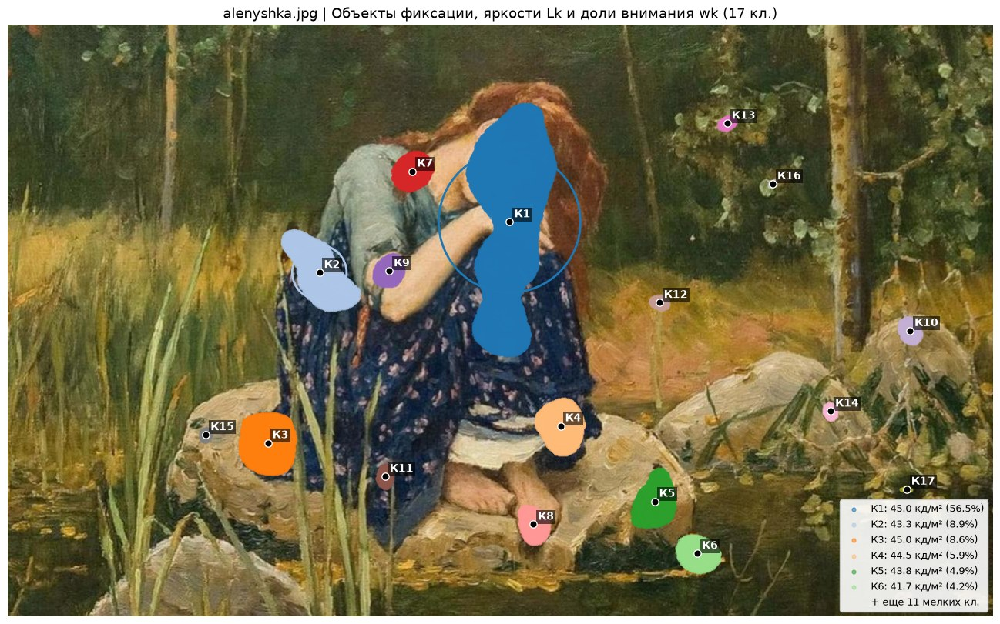

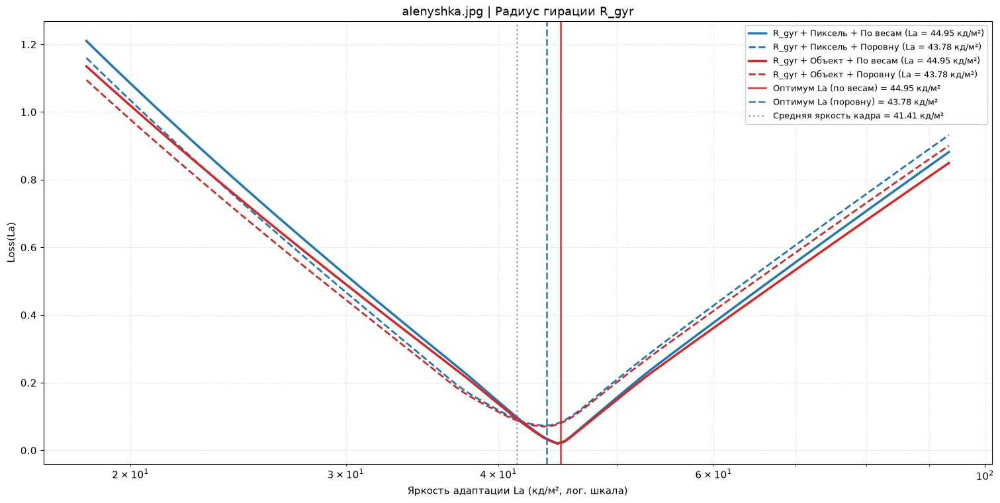

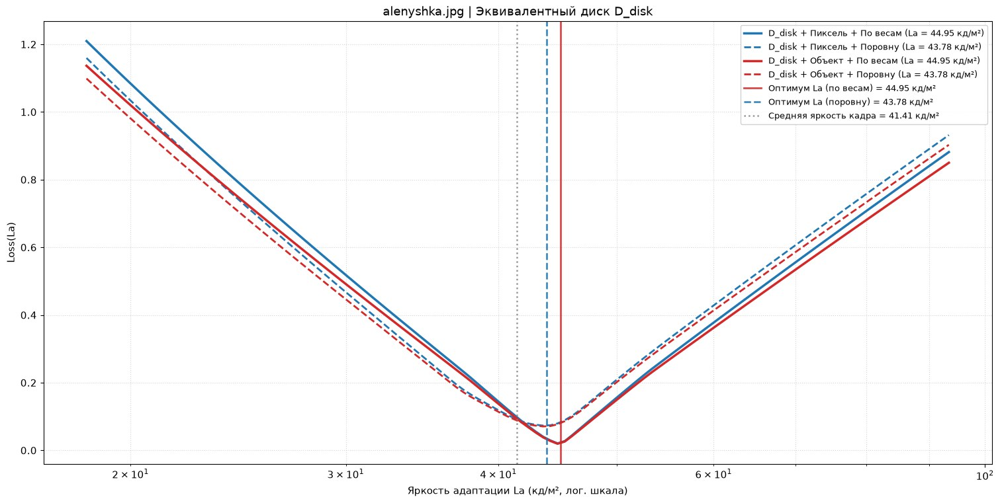

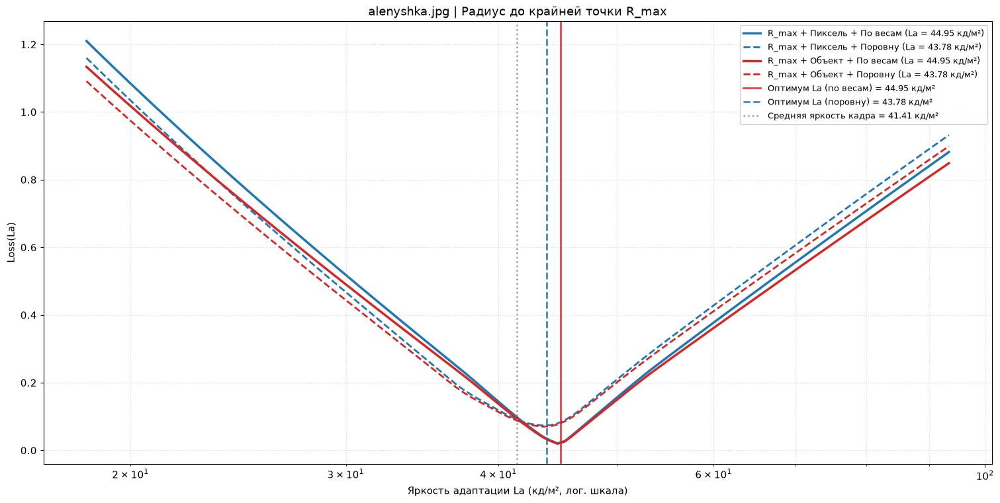

Результаты расчета La (alenyshka.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),43.78,0.0726
1,R_gyr,Пиксель,По весам,44.95,0.0175
2,R_gyr,Объект (R_gyr),Поровну (1/K),43.78,0.0699
3,R_gyr,Объект (R_gyr),По весам,44.95,0.0168
4,D_disk,Пиксель,Поровну (1/K),43.78,0.0726
5,D_disk,Пиксель,По весам,44.95,0.0175
6,D_disk,Объект (D_disk),Поровну (1/K),43.78,0.0702
7,D_disk,Объект (D_disk),По весам,44.95,0.0168
8,R_max,Пиксель,Поровну (1/K),43.78,0.0726
9,R_max,Пиксель,По весам,44.95,0.0175



Объекты фиксации (alenyshka.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,23730,"(651.7, 256.2)",44.95,56.50,40.08,84.94,159.47
1,К2,5499,"(404.5, 322.1)",43.28,8.89,19.30,32.59,61.47
2,К3,4725,"(337.4, 543.8)",45.00,8.65,17.89,25.44,38.64
3,К4,3300,"(717.8, 521.7)",44.53,5.86,14.95,21.44,34.09
4,К5,2964,"(840.0, 619.9)",43.78,4.93,14.17,21.43,39.73
5,К6,2010,"(895.5, 687.7)",41.72,4.21,11.67,16.76,26.62
6,К7,1932,"(525.3, 190.4)",43.82,3.24,11.44,16.34,24.94
7,К8,1464,"(682.4, 649.8)",45.96,2.32,9.96,14.56,24.86
8,К9,1242,"(495.1, 320.1)",45.57,1.87,9.17,13.13,20.33
9,К10,735,"(1171.8, 397.9)",40.47,1.11,7.05,10.23,16.28



Изображение: br_joi.jpg | Разрешение: 1500x999 px
Средняя яркость кадра: 21.80 кд/м² | Медианная: 12.98 кд/м²

Яркости кластеров L_k (13 шт.): [22.9, 18.43, 20.51, 13.79, 54.19, 16.24, 12.79, 12.83, 25.28, 18.95, 14.27, 24.75, 13.4] кд/м²



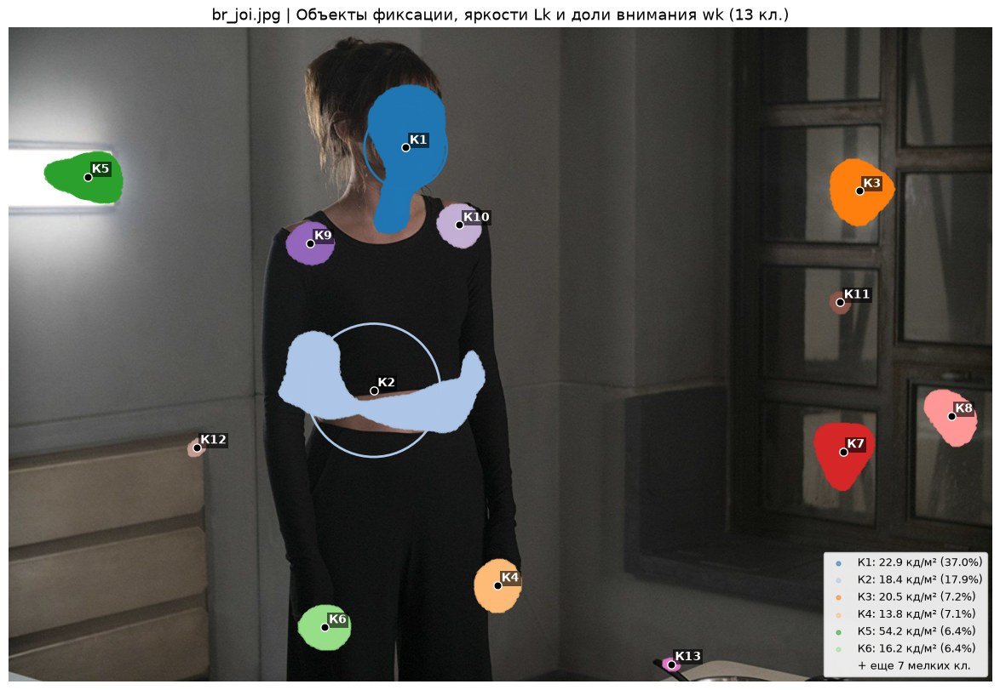

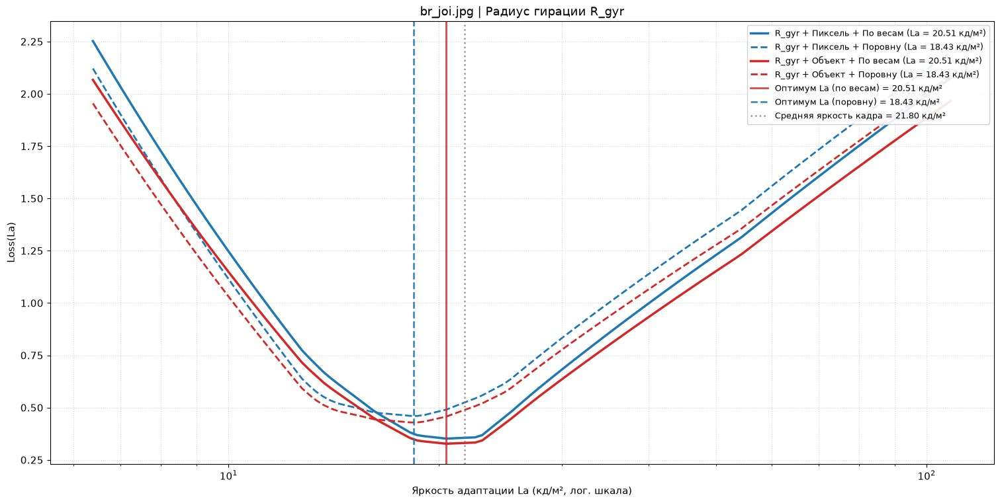

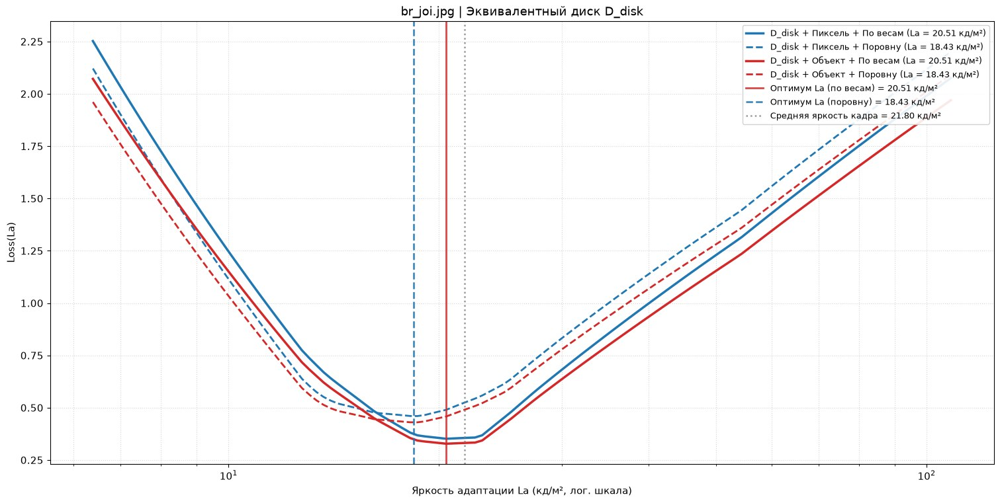

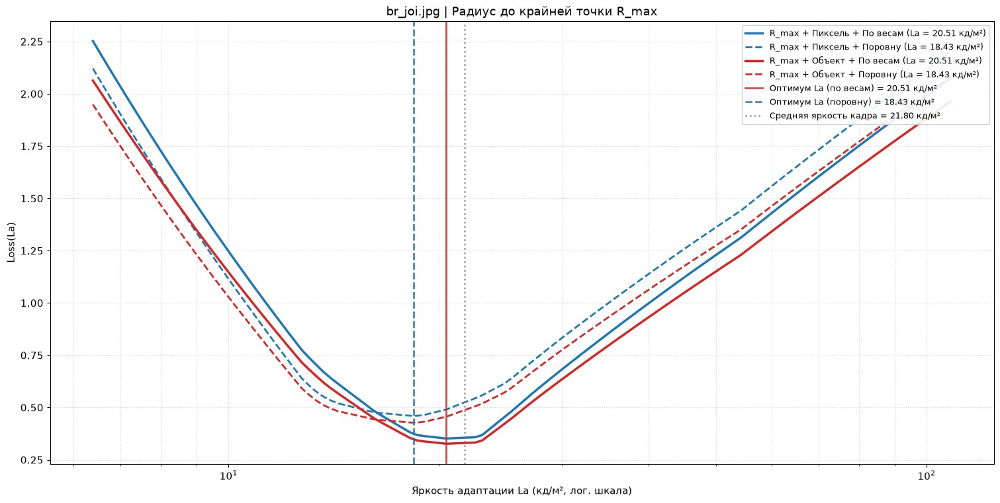

Результаты расчета La (br_joi.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),18.43,0.4587
1,R_gyr,Пиксель,По весам,20.51,0.3515
2,R_gyr,Объект (R_gyr),Поровну (1/K),18.43,0.4275
3,R_gyr,Объект (R_gyr),По весам,20.51,0.3271
4,D_disk,Пиксель,Поровну (1/K),18.43,0.4587
5,D_disk,Пиксель,По весам,20.51,0.3515
6,D_disk,Объект (D_disk),Поровну (1/K),18.43,0.4288
7,D_disk,Объект (D_disk),По весам,20.51,0.3278
8,R_max,Пиксель,Поровну (1/K),18.43,0.4587
9,R_max,Пиксель,По весам,20.51,0.3515



Объекты фиксации (br_joi.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,16820,"(605.1, 183.5)",22.90,36.97,28.80,49.59,103.46
1,К2,19700,"(556.3, 554.0)",18.43,17.91,31.17,80.04,131.90
2,К3,6556,"(1296.7, 249.7)",20.51,7.20,17.98,25.66,39.69
3,К4,4004,"(745.0, 851.7)",13.79,7.12,14.05,19.98,30.50
4,К5,6132,"(120.3, 227.7)",54.19,6.40,17.39,26.87,51.17
5,К6,3772,"(481.9, 915.4)",16.24,6.38,13.64,19.41,30.25
6,К7,6192,"(1271.9, 647.6)",12.79,5.73,17.47,25.44,44.46
7,К8,4264,"(1436.8, 593.3)",12.83,4.19,14.50,21.46,35.45
8,К9,3160,"(459.8, 329.6)",25.28,3.65,12.48,17.75,27.39
9,К10,3020,"(687.0, 301.5)",18.95,3.54,12.20,17.30,25.56



Изображение: landscape.jpg | Разрешение: 740x415 px
Средняя яркость кадра: 43.59 кд/м² | Медианная: 26.98 кд/м²

Яркости кластеров L_k (5 шт.): [41.03, 48.31, 44.4, 31.52, 29.92] кд/м²



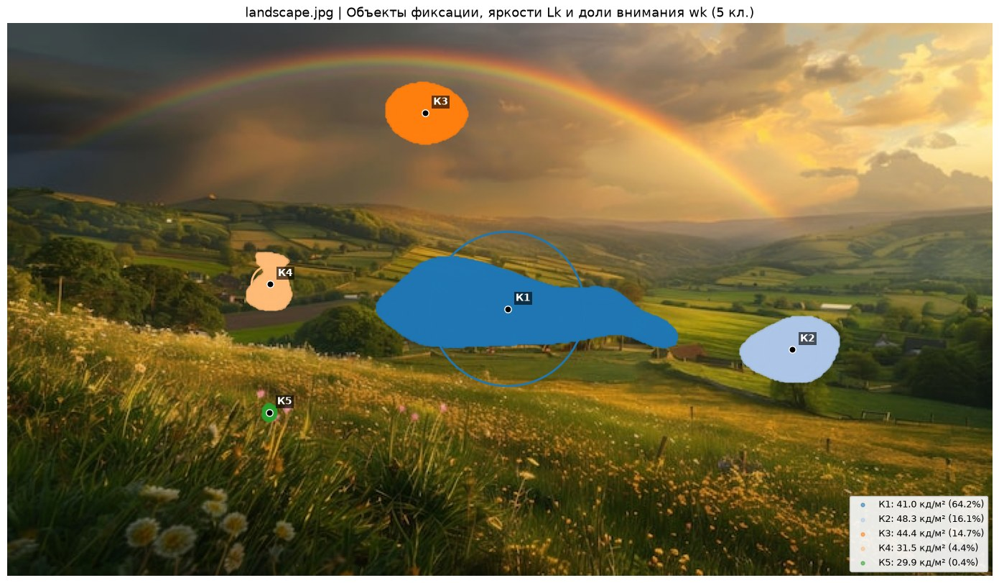

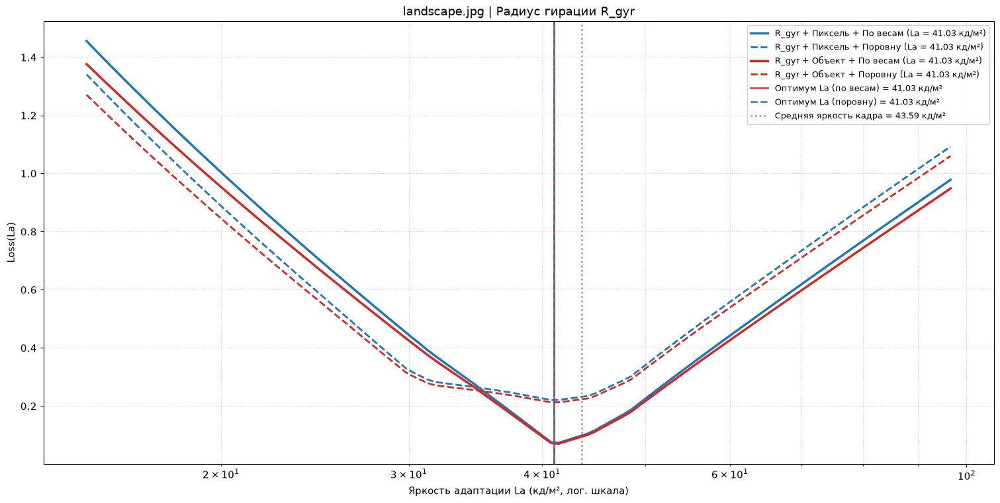

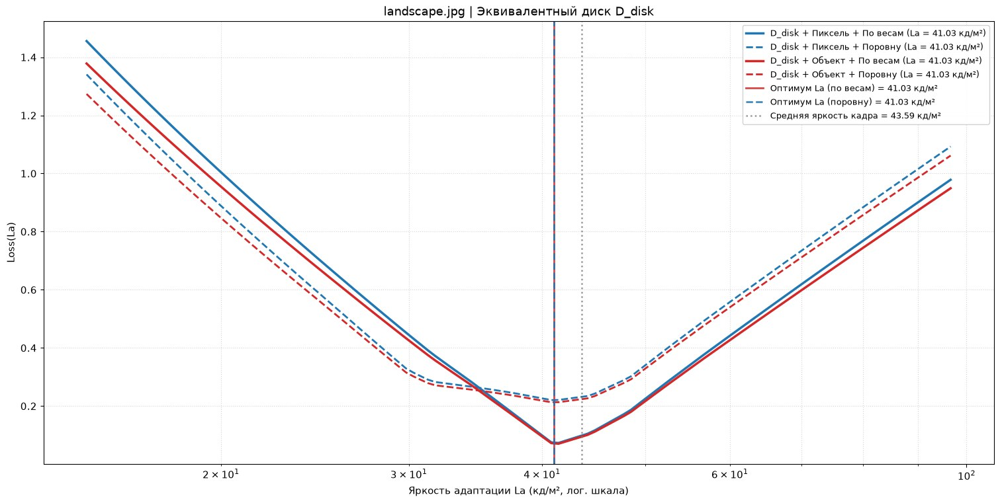

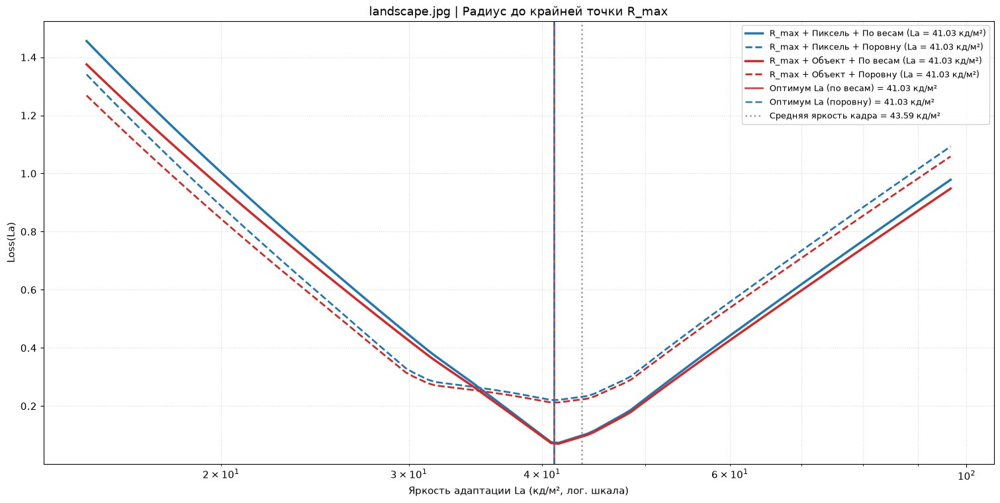

Результаты расчета La (landscape.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),41.03,0.2188
1,R_gyr,Пиксель,По весам,41.03,0.0680
2,R_gyr,Объект (R_gyr),Поровну (1/K),41.03,0.2107
3,R_gyr,Объект (R_gyr),По весам,41.03,0.0655
4,D_disk,Пиксель,Поровну (1/K),41.03,0.2188
5,D_disk,Пиксель,По весам,41.03,0.0680
6,D_disk,Объект (D_disk),Поровну (1/K),41.03,0.2112
7,D_disk,Объект (D_disk),По весам,41.03,0.0656
8,R_max,Пиксель,Поровну (1/K),41.03,0.2188
9,R_max,Пиксель,По весам,41.03,0.0680



Объекты фиксации (landscape.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,9630,"(375.4, 214.2)",41.03,64.24,44.17,92.37,205.24
1,К2,2623,"(589.1, 244.6)",48.31,16.15,23.05,34.27,61.09
2,К3,2055,"(313.6, 66.9)",44.40,14.74,20.40,29.52,48.65
3,К4,950,"(196.8, 195.5)",31.52,4.43,13.87,21.94,38.60
4,К5,97,"(196.3, 291.8)",29.92,0.45,4.43,6.33,9.96



Изображение: photo_flower.jpg | Разрешение: 736x913 px
Средняя яркость кадра: 39.48 кд/м² | Медианная: 23.95 кд/м²

Яркости кластеров L_k (7 шт.): [32.54, 64.93, 46.08, 28.89, 32.37, 35.31, 25.35] кд/м²



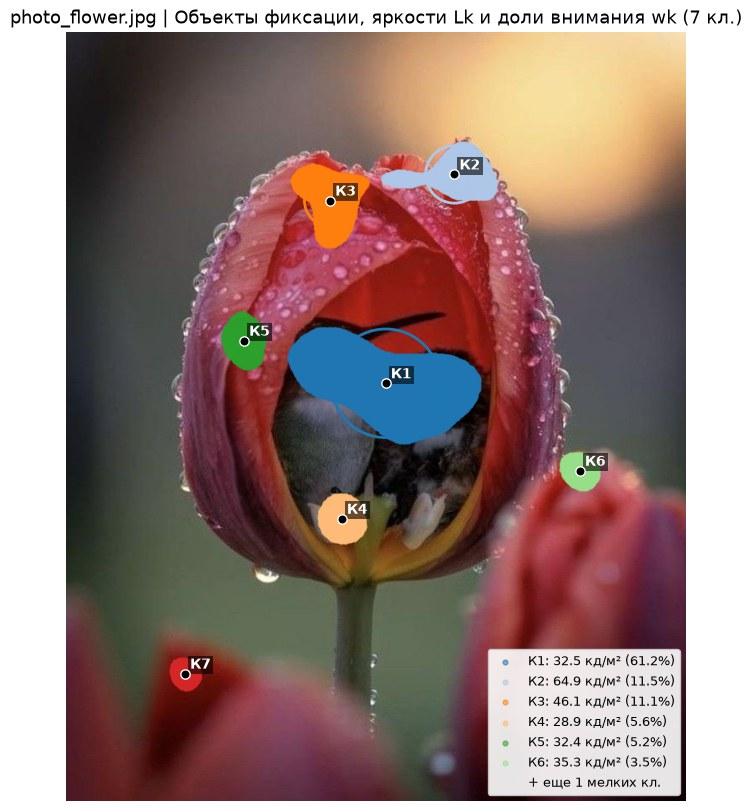

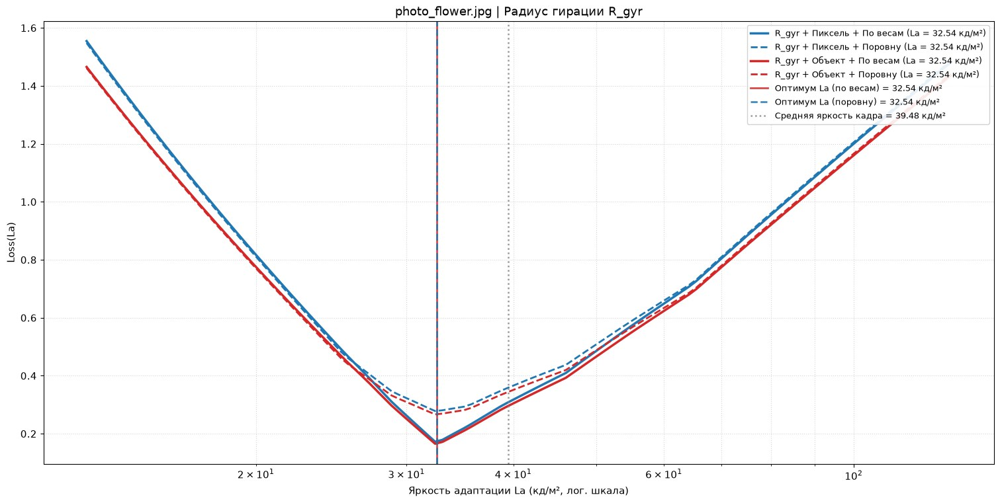

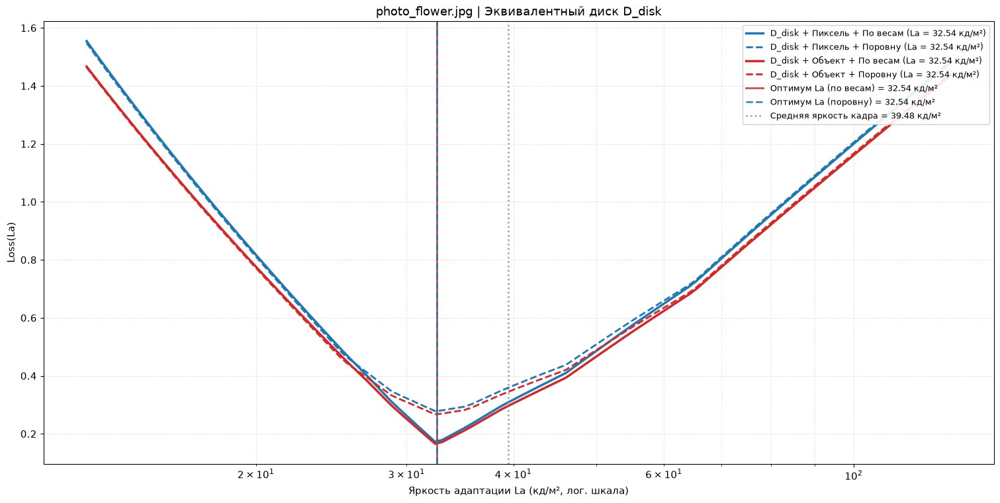

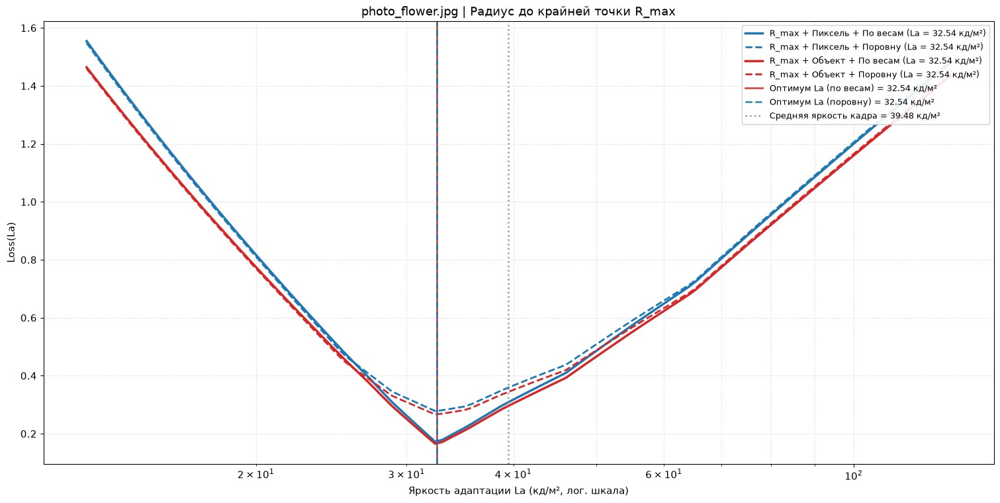

Результаты расчета La (photo_flower.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),32.54,0.2775
1,R_gyr,Пиксель,По весам,32.54,0.1681
2,R_gyr,Объект (R_gyr),Поровну (1/K),32.54,0.2661
3,R_gyr,Объект (R_gyr),По весам,32.54,0.1614
4,D_disk,Пиксель,Поровну (1/K),32.54,0.2775
5,D_disk,Пиксель,По весам,32.54,0.1681
6,D_disk,Объект (D_disk),Поровну (1/K),32.54,0.2664
7,D_disk,Объект (D_disk),По весам,32.54,0.1616
8,R_max,Пиксель,Поровну (1/K),32.54,0.2775
9,R_max,Пиксель,По весам,32.54,0.1681



Объекты фиксации (photo_flower.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,17862,"(378.9, 416.7)",32.54,61.24,60.48,103.38,190.04
1,К2,4226,"(460.3, 168.8)",64.93,11.45,29.42,54.61,135.44
2,К3,4784,"(312.9, 199.9)",46.08,11.08,31.30,48.90,84.15
3,К4,2252,"(326.7, 577.5)",28.89,5.58,21.48,30.45,45.23
4,К5,2272,"(210.7, 366.2)",32.37,5.18,21.57,31.27,51.21
5,К6,1346,"(609.2, 520.6)",35.31,3.48,16.60,23.76,38.25
6,К7,858,"(140.6, 761.3)",25.35,2.00,13.26,18.90,29.61



Изображение: photo_woman.jpg | Разрешение: 736x1098 px
Средняя яркость кадра: 127.82 кд/м² | Медианная: 137.31 кд/м²

Яркости кластеров L_k (9 шт.): [126.89, 134.6, 96.96, 108.81, 145.08, 97.84, 125.45, 84.14, 110.72] кд/м²



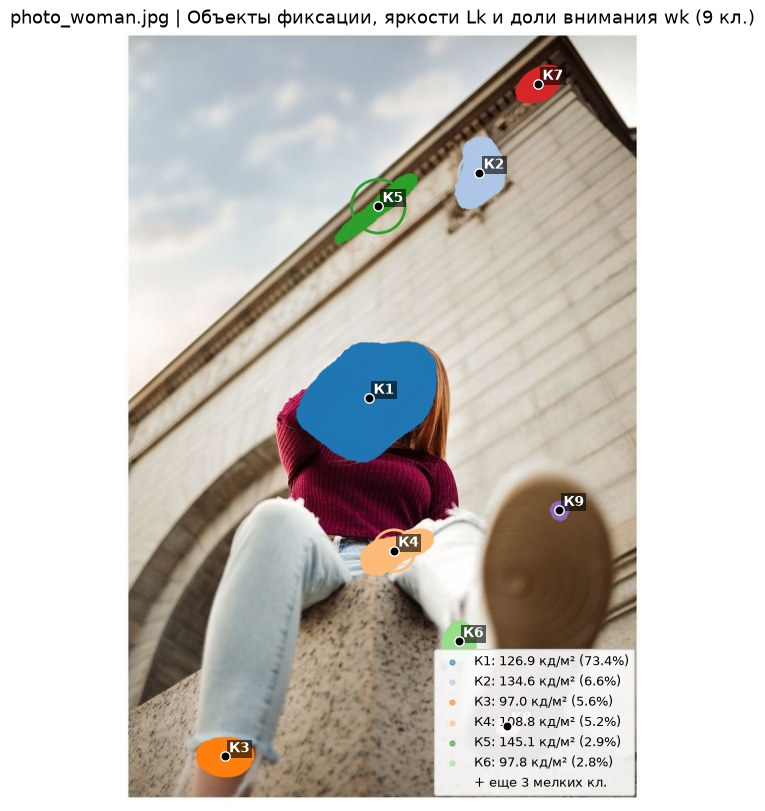

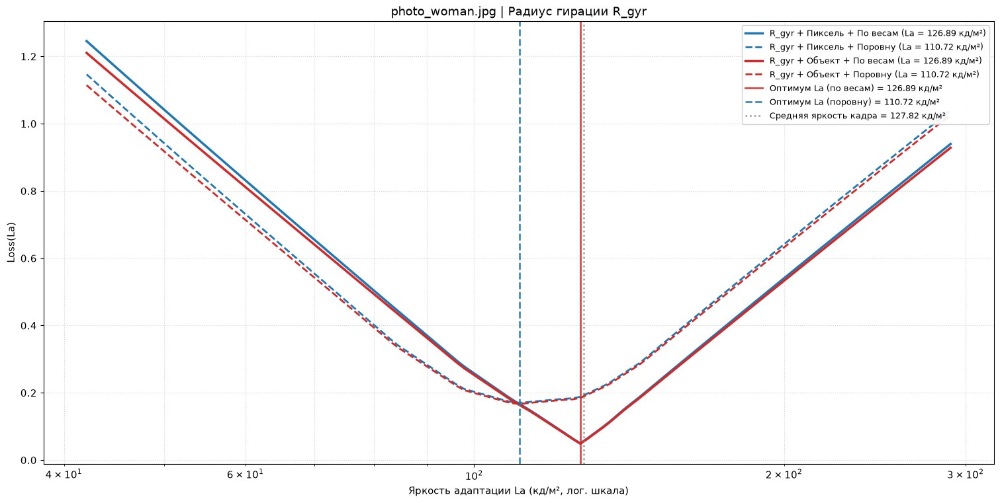

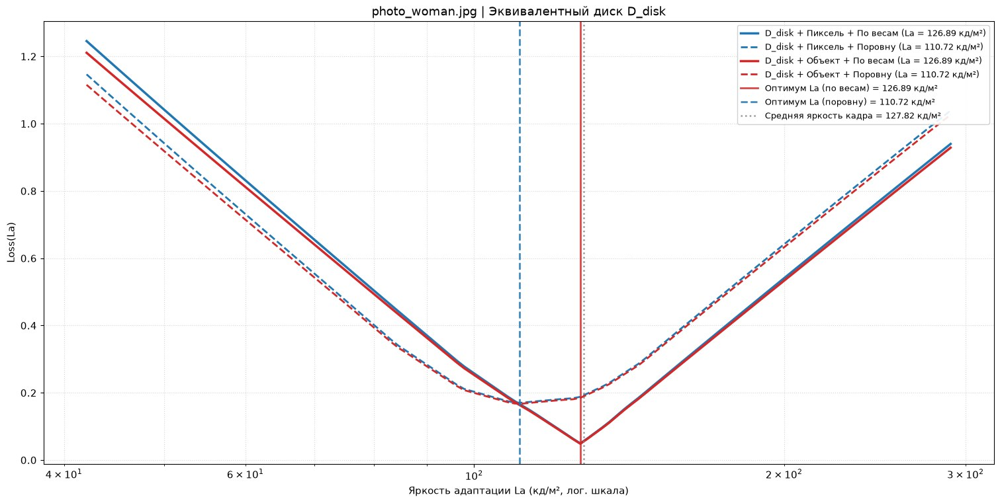

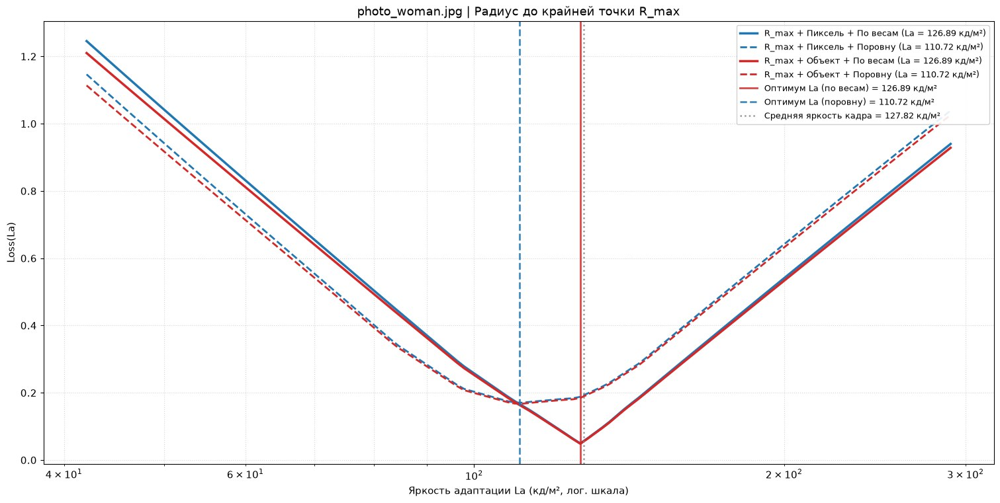

Результаты расчета La (photo_woman.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),110.72,0.1696
1,R_gyr,Пиксель,По весам,126.89,0.0490
2,R_gyr,Объект (R_gyr),Поровну (1/K),110.72,0.1667
3,R_gyr,Объект (R_gyr),По весам,126.89,0.0482
4,D_disk,Пиксель,Поровну (1/K),110.72,0.1696
5,D_disk,Пиксель,По весам,126.89,0.0490
6,D_disk,Объект (D_disk),Поровну (1/K),110.72,0.1668
7,D_disk,Объект (D_disk),По весам,126.89,0.0482
8,R_max,Пиксель,Поровну (1/K),110.72,0.1696
9,R_max,Пиксель,По весам,126.89,0.0490



Объекты фиксации (photo_woman.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,22686,"(348.6, 522.1)",126.89,73.35,68.16,99.66,167.85
1,К2,4476,"(505.8, 200.7)",134.60,6.58,30.28,46.61,82.76
2,К3,3024,"(142.4, 1033.8)",96.96,5.55,24.89,36.77,61.34
3,К4,3318,"(383.9, 740.2)",108.81,5.15,26.07,47.69,90.27
4,К5,2322,"(361.5, 248.5)",145.08,2.93,21.81,61.32,119.66
5,К6,1749,"(476.3, 869.6)",97.84,2.78,18.93,27.10,42.94
6,К7,2010,"(589.8, 73.9)",125.45,2.63,20.29,30.65,53.81
7,К8,480,"(544.7, 990.8)",84.14,0.61,9.91,14.40,23.16
8,К9,342,"(619.8, 682.3)",110.72,0.42,8.37,11.83,17.26



Изображение: Rosenblatt.jpg | Разрешение: 387x429 px
Средняя яркость кадра: 33.05 кд/м² | Медианная: 8.29 кд/м²

Яркости кластеров L_k (2 шт.): [31.29, 23.02] кд/м²



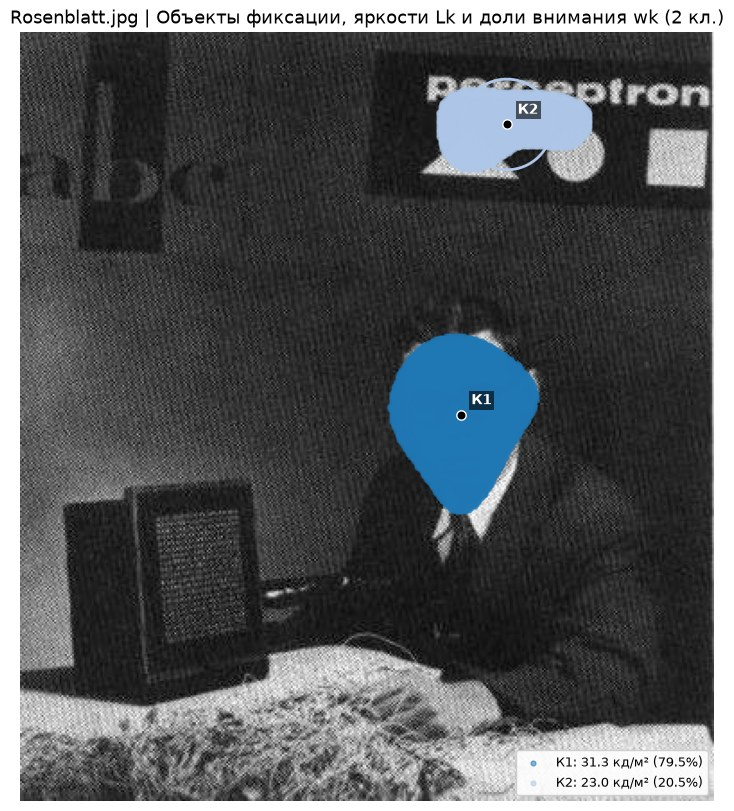

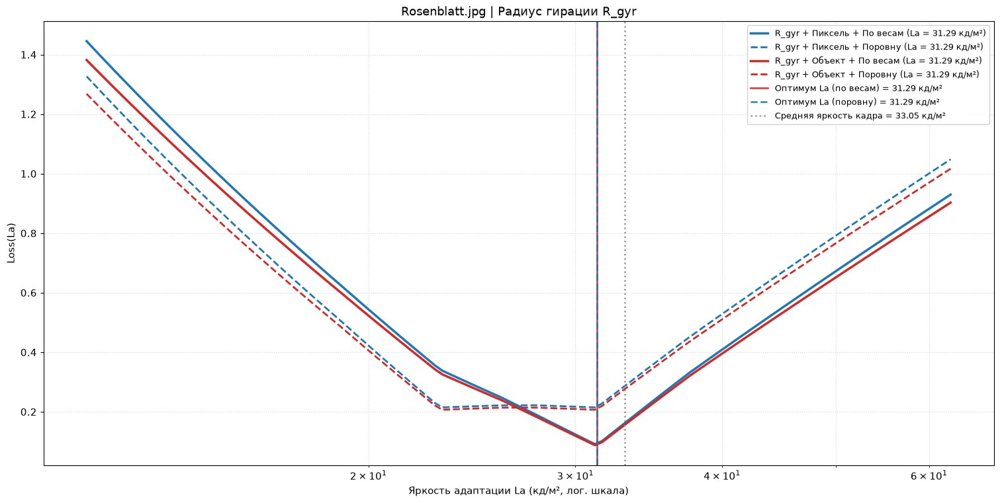

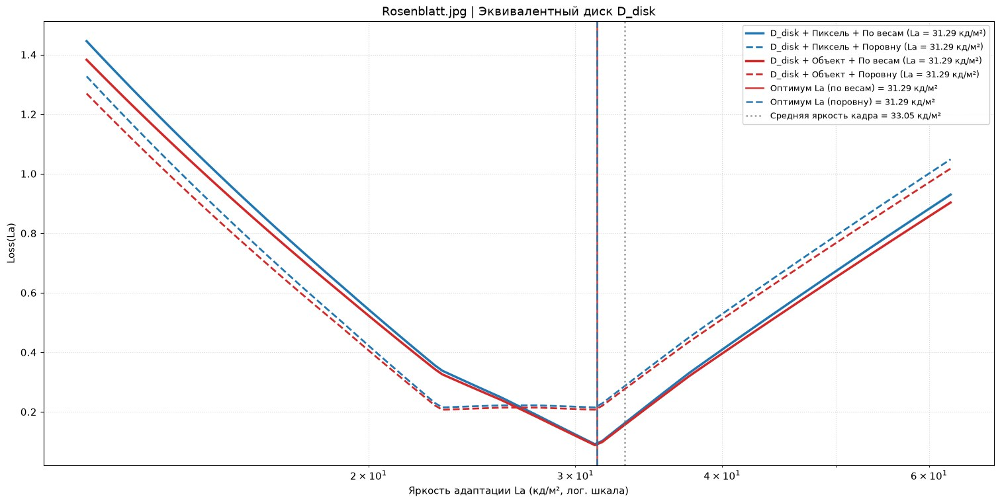

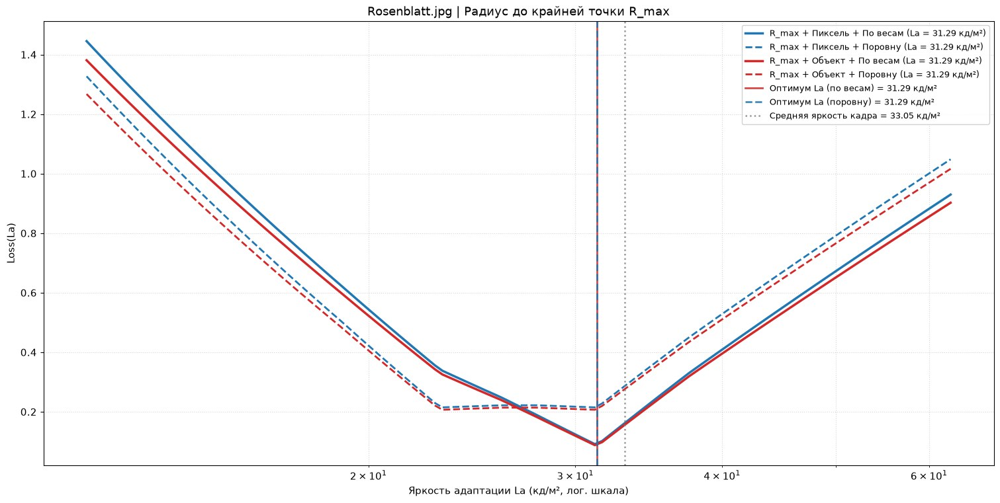

Результаты расчета La (Rosenblatt.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),31.29,0.2145
1,R_gyr,Пиксель,По весам,31.29,0.0878
2,R_gyr,Объект (R_gyr),Поровну (1/K),31.29,0.2067
3,R_gyr,Объект (R_gyr),По весам,31.29,0.0846
4,D_disk,Пиксель,Поровну (1/K),31.29,0.2145
5,D_disk,Пиксель,По весам,31.29,0.0878
6,D_disk,Объект (D_disk),Поровну (1/K),31.29,0.2069
7,D_disk,Объект (D_disk),По весам,31.29,0.0847
8,R_max,Пиксель,Поровну (1/K),31.29,0.2145
9,R_max,Пиксель,По весам,31.29,0.0878



Объекты фиксации (Rosenblatt.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,5449,"(245.1, 213.2)",31.29,79.52,63.53,92.15,164.56
1,К2,2853,"(271.0, 51.2)",23.02,20.48,45.97,77.14,141.70



Изображение: tiger.jpg | Разрешение: 736x1104 px
Средняя яркость кадра: 68.19 кд/м² | Медианная: 54.41 кд/м²

Яркости кластеров L_k (5 шт.): [61.02, 48.38, 84.81, 55.8, 88.19] кд/м²



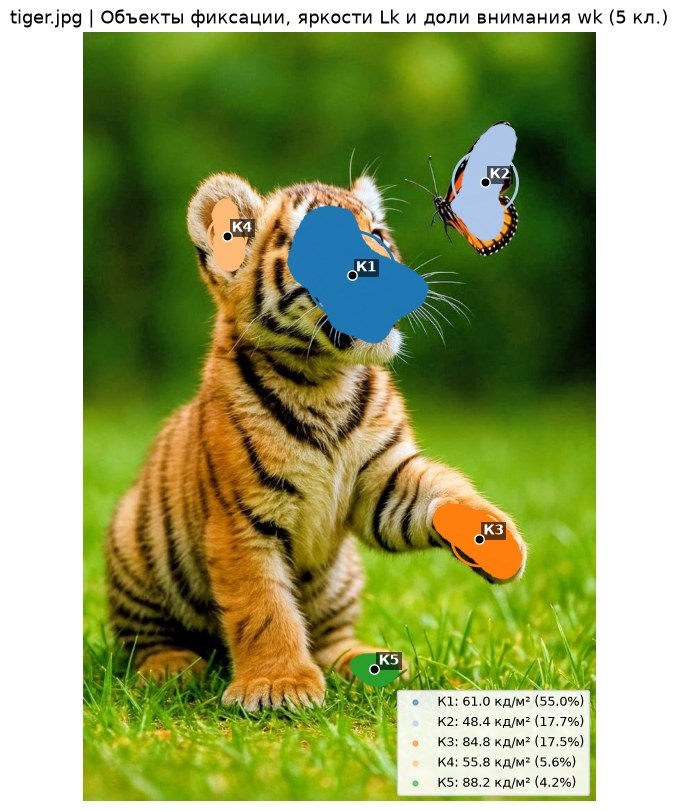

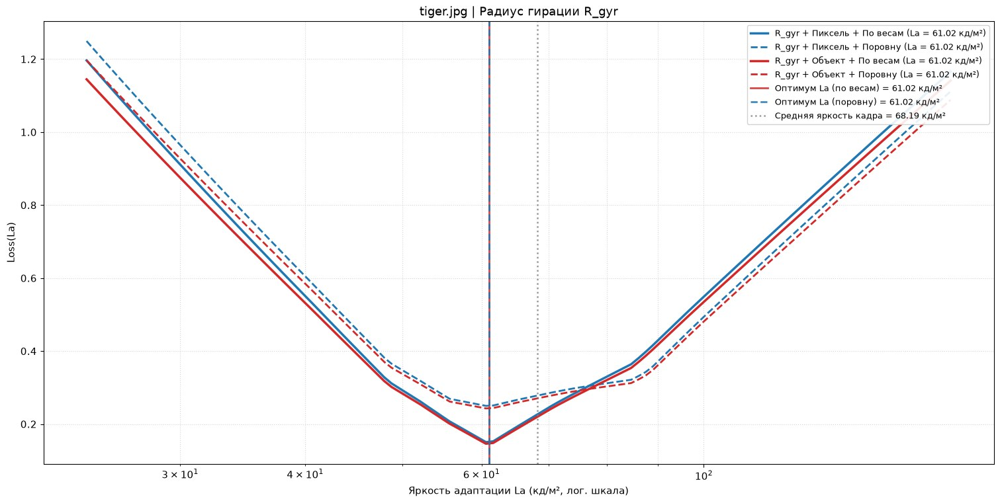

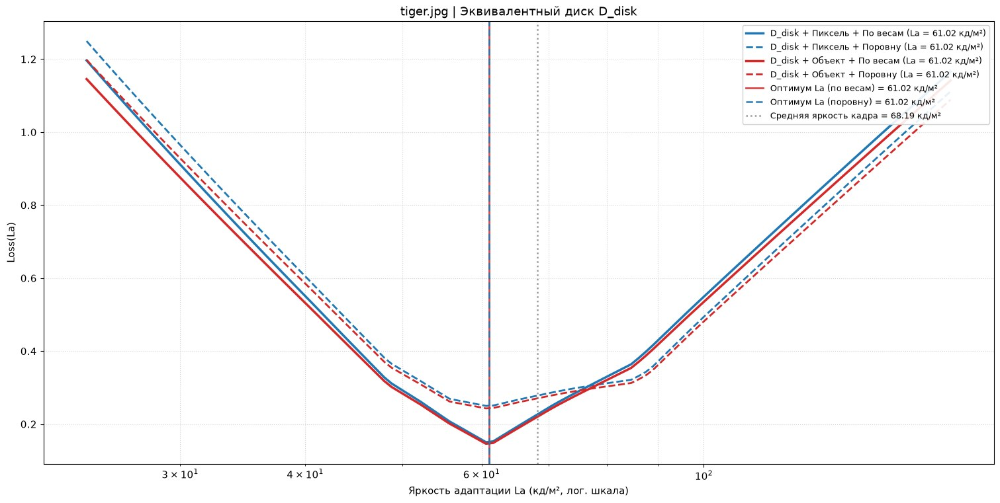

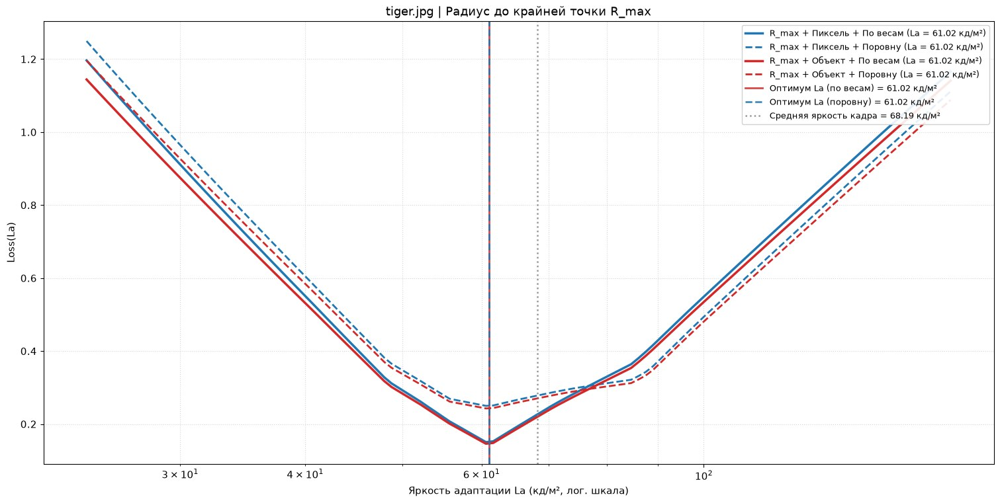

Результаты расчета La (tiger.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),61.02,0.2482
1,R_gyr,Пиксель,По весам,61.02,0.1456
2,R_gyr,Объект (R_gyr),Поровну (1/K),61.02,0.2413
3,R_gyr,Объект (R_gyr),По весам,61.02,0.1414
4,D_disk,Пиксель,Поровну (1/K),61.02,0.2482
5,D_disk,Пиксель,По весам,61.02,0.1456
6,D_disk,Объект (D_disk),Поровну (1/K),61.02,0.2414
7,D_disk,Объект (D_disk),По весам,61.02,0.1415
8,R_max,Пиксель,Поровну (1/K),61.02,0.2482
9,R_max,Пиксель,По весам,61.02,0.1456



Объекты фиксации (tiger.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,20898,"(385.5, 349.2)",61.02,55.01,65.42,101.92,171.58
1,К2,7983,"(577.2, 215.7)",48.38,17.74,40.43,74.25,136.03
2,К3,6723,"(568.4, 726.9)",84.81,17.48,37.11,62.90,113.93
3,К4,3063,"(207.1, 292.3)",55.80,5.60,25.05,43.98,79.73
4,К5,1962,"(418.0, 913.7)",88.19,4.17,20.04,29.98,52.82


In [11]:
for img_path in EXAMPLE_IMAGES:
    run_experiment_4(img_path)


## Прогон на examples_old_jnd

Изображений в examples_old_jnd/: 7
Изображение: 1.jpg | Разрешение: 626x274 px
Средняя яркость кадра: 108.73 кд/м² | Медианная: 102.54 кд/м²

Яркости кластеров L_k (2 шт.): [126.24, 118.22] кд/м²



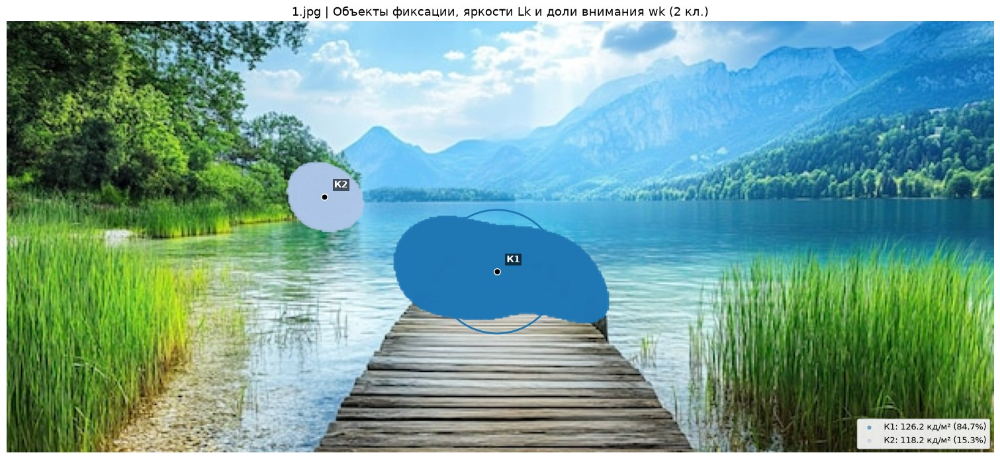

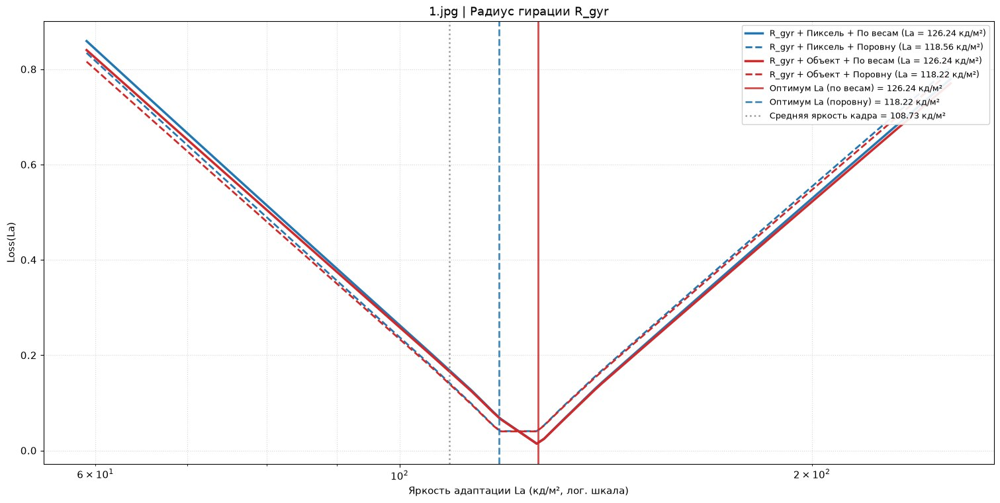

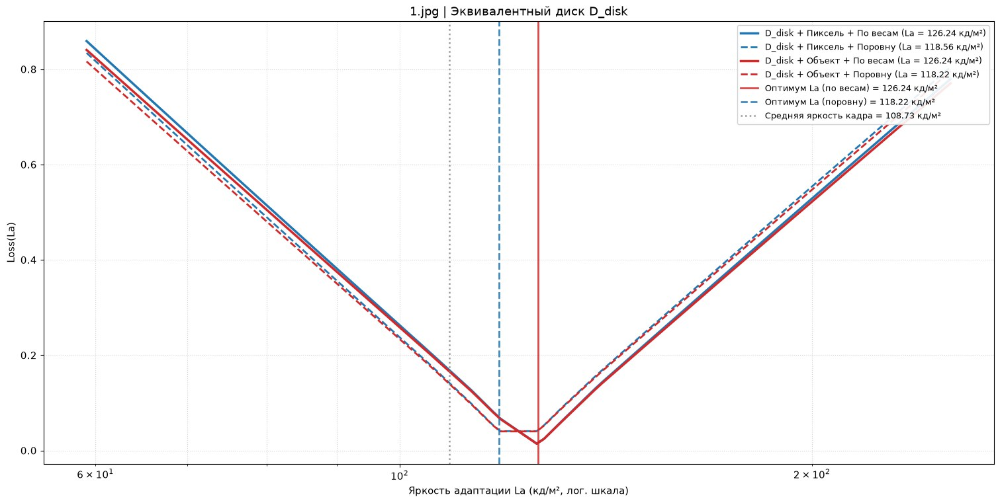

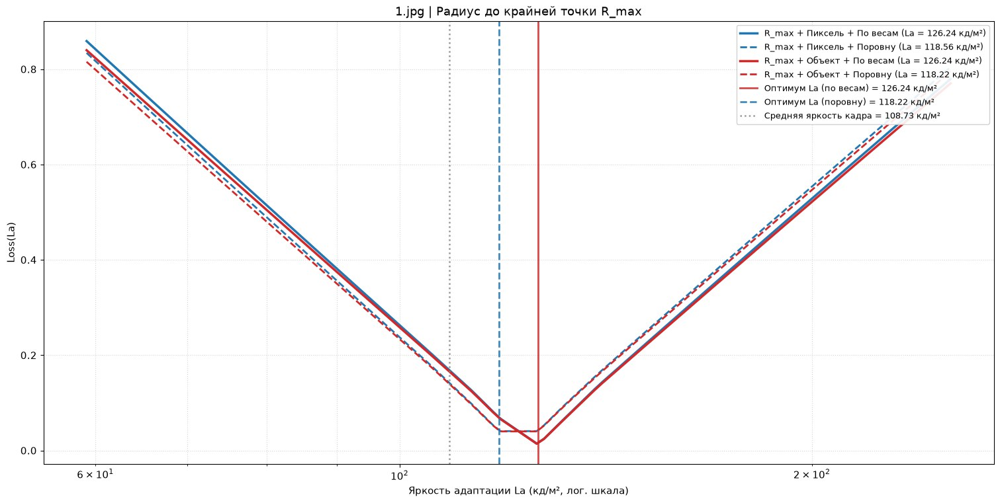

Результаты расчета La (1.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),118.56,0.0406
1,R_gyr,Пиксель,По весам,126.24,0.0124
2,R_gyr,Объект (R_gyr),Поровну (1/K),118.22,0.0400
3,R_gyr,Объект (R_gyr),По весам,126.24,0.0122
4,D_disk,Пиксель,Поровну (1/K),118.56,0.0406
5,D_disk,Пиксель,По весам,126.24,0.0124
6,D_disk,Объект (D_disk),Поровну (1/K),118.22,0.0400
7,D_disk,Объект (D_disk),По весам,126.24,0.0122
8,R_max,Пиксель,Поровну (1/K),118.56,0.0406
9,R_max,Пиксель,По весам,126.24,0.0124



Объекты фиксации (1.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,6996,"(310.5, 158.7)",126.24,84.74,44.50,74.03,138.29
1,К2,1581,"(201.1, 111.1)",118.22,15.26,21.16,30.22,46.99



Изображение: 2.jpg | Разрешение: 640x360 px
Средняя яркость кадра: 21.47 кд/м² | Медианная: 9.32 кд/м²

Яркости кластеров L_k (6 шт.): [27.45, 22.81, 16.86, 20.95, 22.46, 21.97] кд/м²



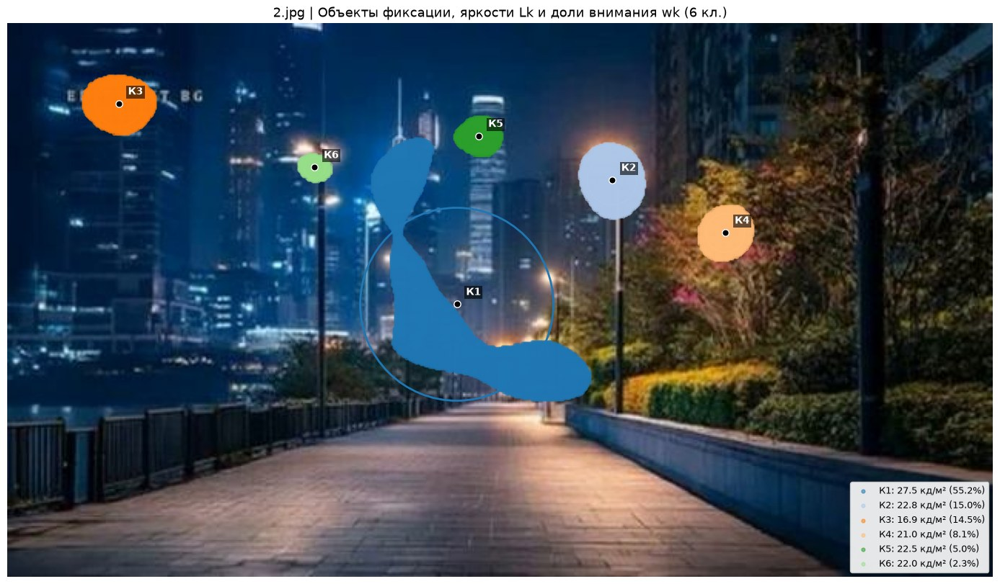

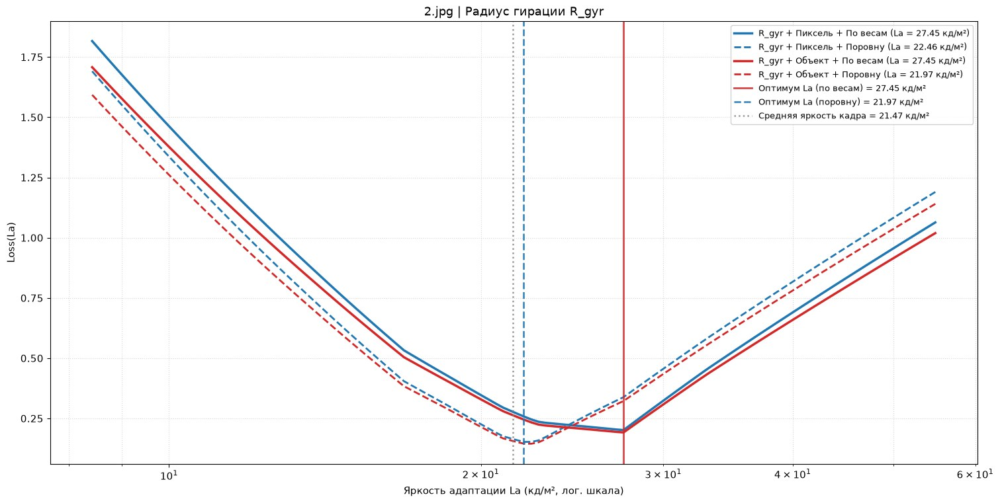

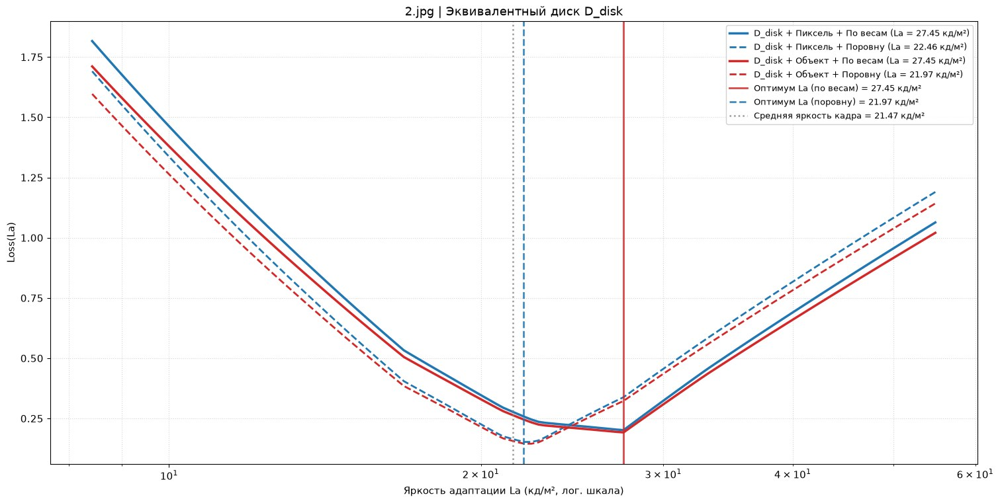

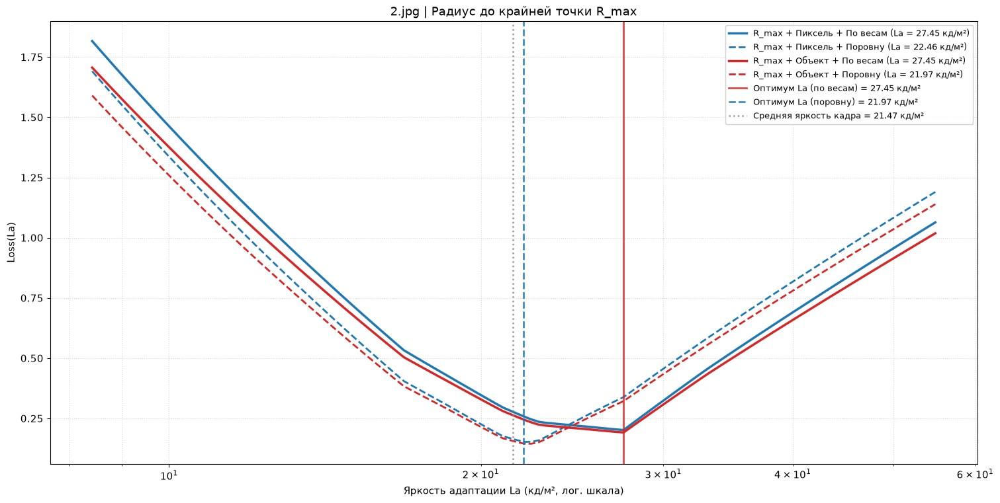

Результаты расчета La (2.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),22.46,0.1525
1,R_gyr,Пиксель,По весам,27.45,0.2010
2,R_gyr,Объект (R_gyr),Поровну (1/K),21.97,0.1449
3,R_gyr,Объект (R_gyr),По весам,27.45,0.1912
4,D_disk,Пиксель,Поровну (1/K),22.46,0.1525
5,D_disk,Пиксель,По весам,27.45,0.2010
6,D_disk,Объект (D_disk),Поровну (1/K),21.97,0.1451
7,D_disk,Объект (D_disk),По весам,27.45,0.1915
8,R_max,Пиксель,Поровну (1/K),22.46,0.1525
9,R_max,Пиксель,По весам,27.45,0.2010



Объекты фиксации (2.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,6667,"(291.4, 182.3)",27.45,55.16,42.49,115.67,204.53
1,К2,1595,"(392.1, 101.6)",22.81,14.97,20.78,29.62,45.29
2,К3,1387,"(71.9, 52.0)",16.86,14.47,19.38,27.76,43.55
3,К4,987,"(465.8, 135.9)",20.95,8.13,16.35,23.21,35.09
4,К5,591,"(305.8, 73.1)",22.46,4.97,12.65,18.10,29.29
5,К6,293,"(199.0, 93.4)",21.97,2.30,8.91,12.75,19.62



Изображение: 3.jpg | Разрешение: 640x640 px
Средняя яркость кадра: 14.53 кд/м² | Медианная: 8.19 кд/м²

Яркости кластеров L_k (4 шт.): [17.88, 14.94, 15.49, 14.63] кд/м²



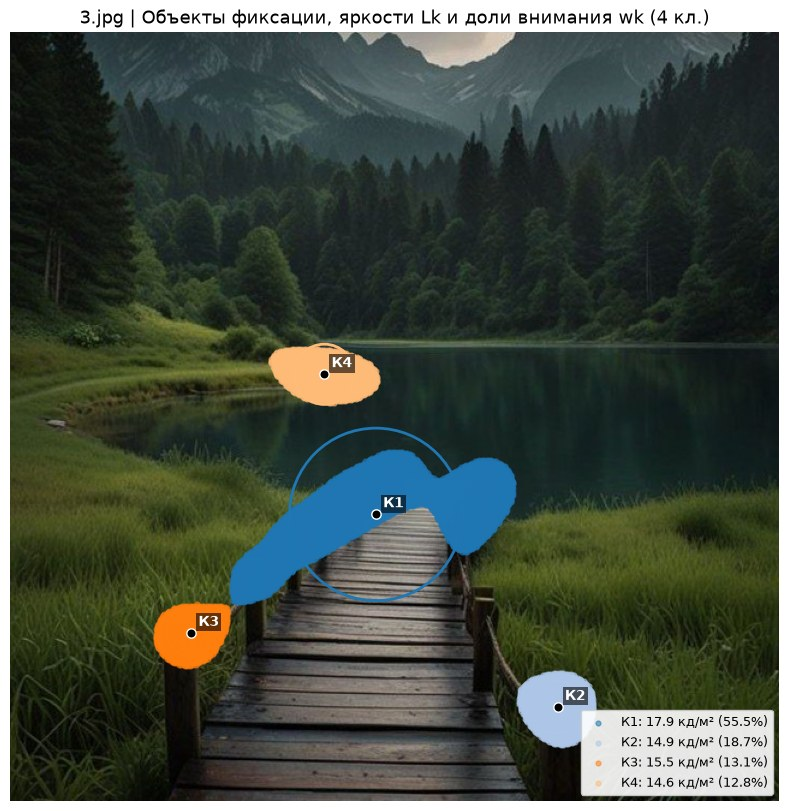

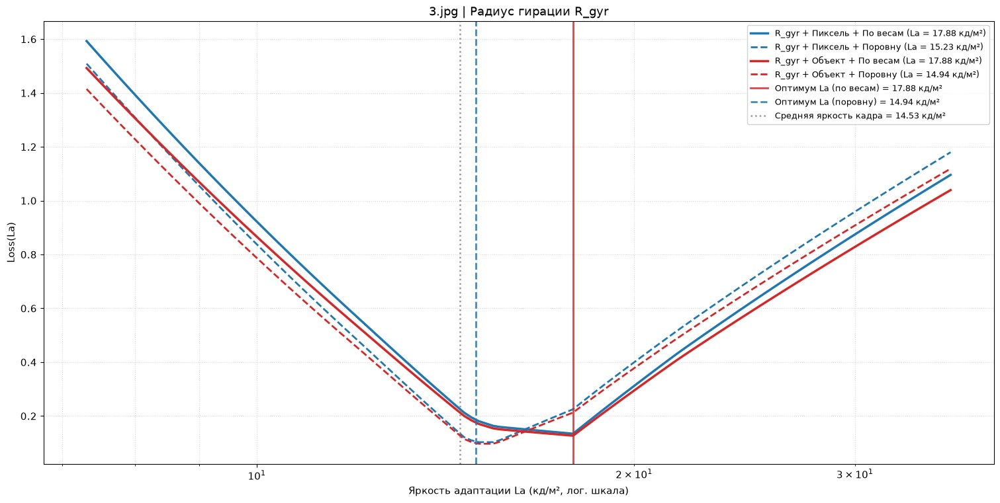

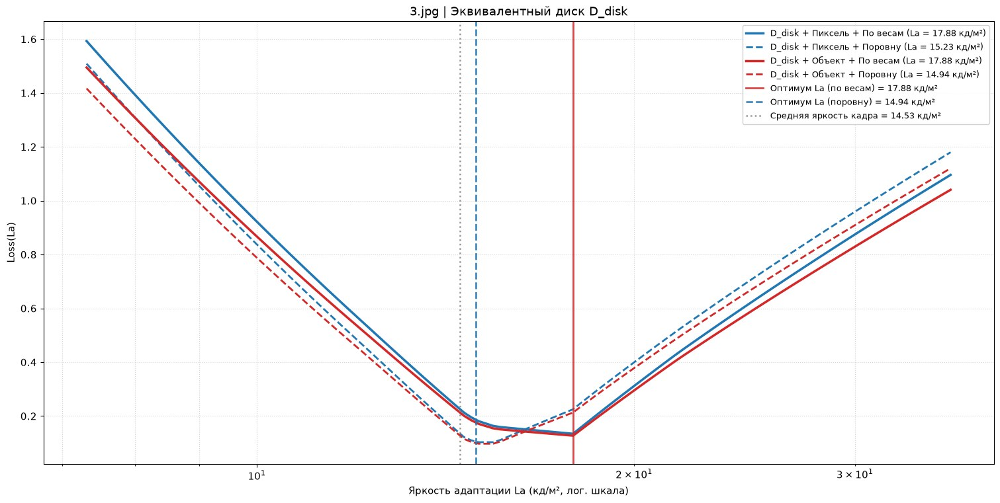

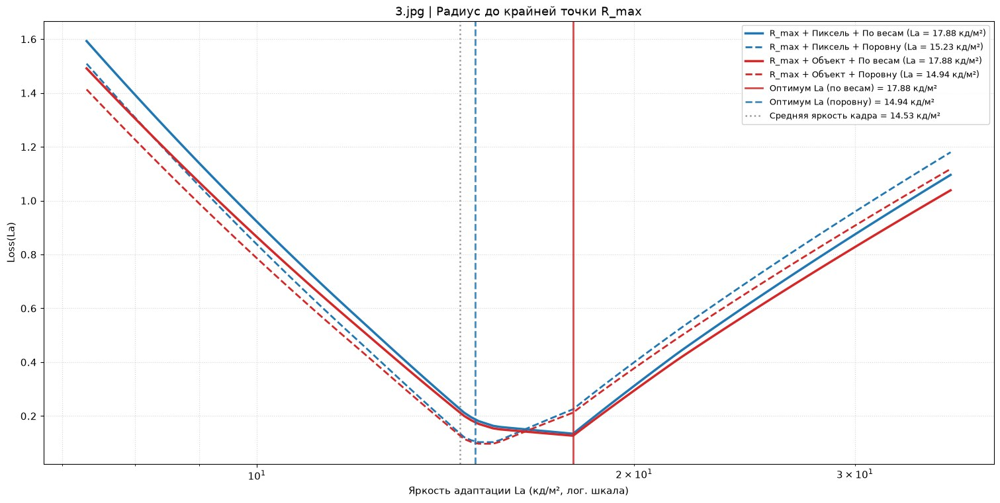

Результаты расчета La (3.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),15.23,0.1028
1,R_gyr,Пиксель,По весам,17.88,0.1342
2,R_gyr,Объект (R_gyr),Поровну (1/K),14.94,0.0971
3,R_gyr,Объект (R_gyr),По весам,17.88,0.1268
4,D_disk,Пиксель,Поровну (1/K),15.23,0.1028
5,D_disk,Пиксель,По весам,17.88,0.1342
6,D_disk,Объект (D_disk),Поровну (1/K),14.94,0.0972
7,D_disk,Объект (D_disk),По весам,17.88,0.1270
8,R_max,Пиксель,Поровну (1/K),15.23,0.1028
9,R_max,Пиксель,По весам,17.88,0.1342



Объекты фиксации (3.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,11952,"(304.0, 401.0)",17.88,55.45,56.89,132.42,256.49
1,К2,2958,"(455.2, 561.4)",14.94,18.72,28.30,40.23,63.32
2,К3,2454,"(150.2, 499.8)",15.49,13.08,25.78,37.32,66.99
3,К4,3116,"(261.0, 284.5)",14.63,12.75,29.05,46.25,84.44



Изображение: 4.jpg | Разрешение: 625x352 px
Средняя яркость кадра: 100.38 кд/м² | Медианная: 71.37 кд/м²

Яркости кластеров L_k (13 шт.): [97.8, 92.94, 100.31, 100.89, 95.84, 104.14, 95.0, 100.74, 103.55, 100.65, 94.81, 92.55, 94.85] кд/м²



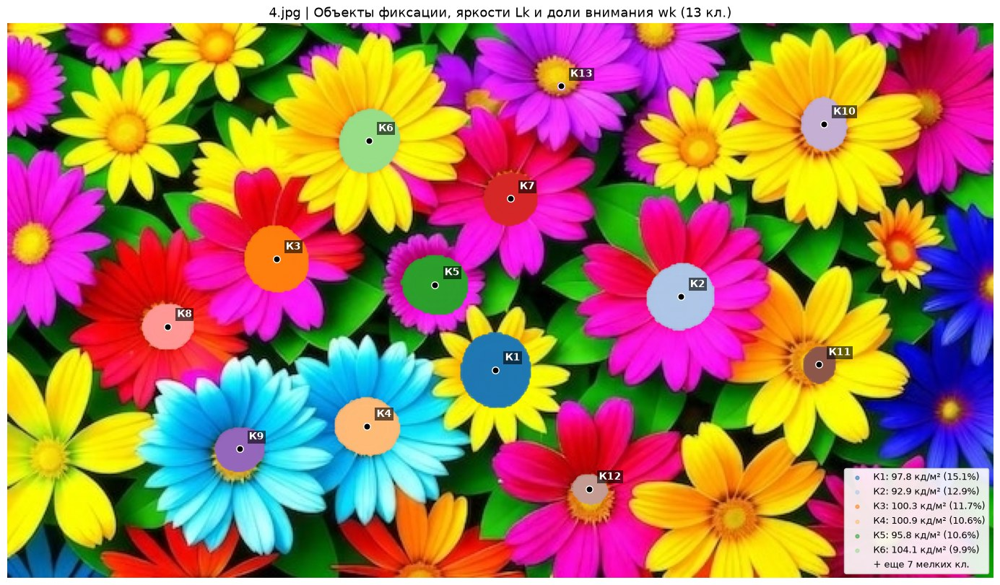

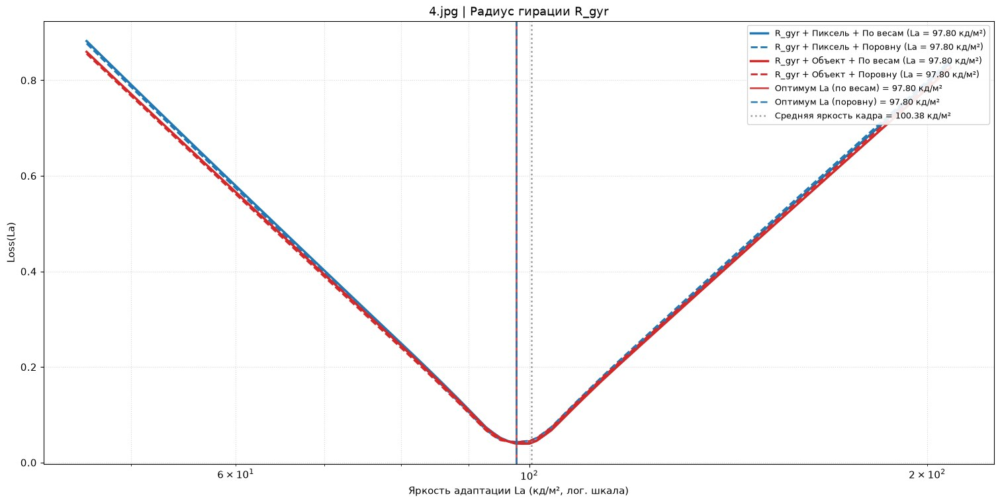

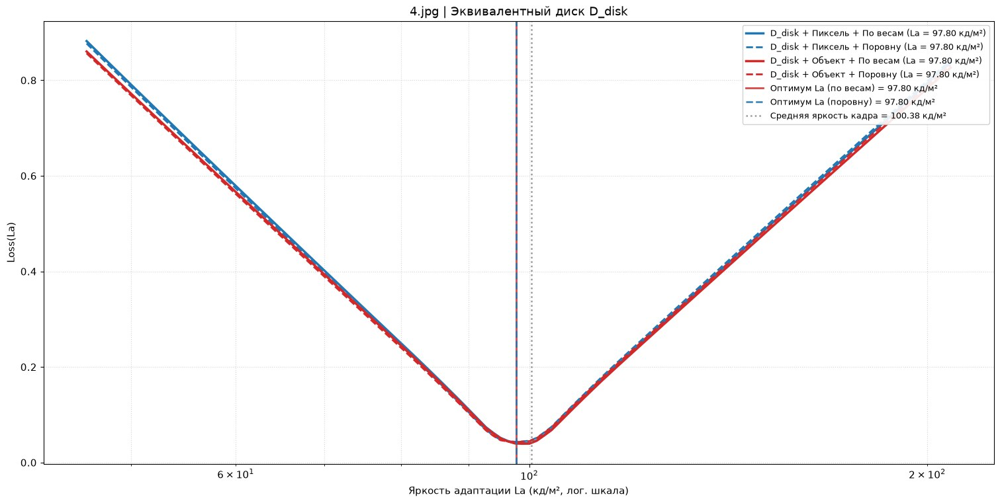

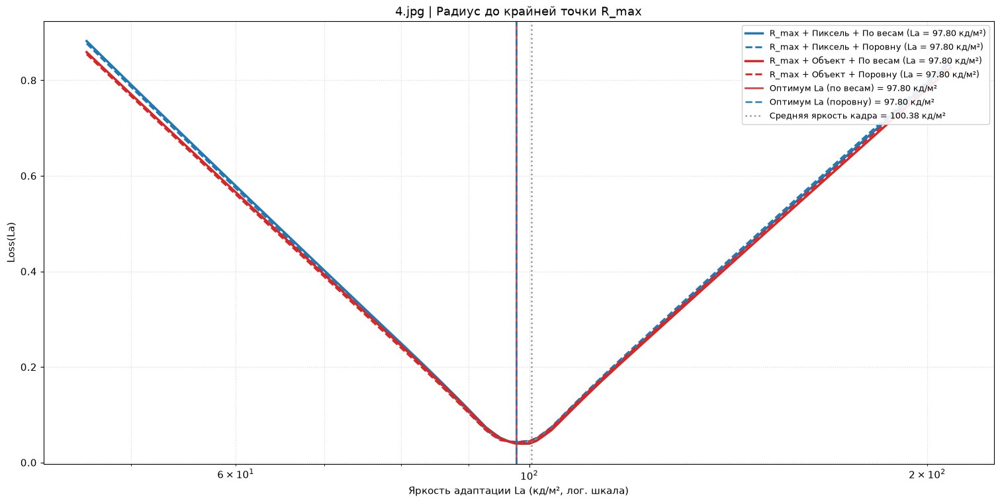

Результаты расчета La (4.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),97.8,0.0433
1,R_gyr,Пиксель,По весам,97.8,0.0398
2,R_gyr,Объект (R_gyr),Поровну (1/K),97.8,0.0426
3,R_gyr,Объект (R_gyr),По весам,97.8,0.0391
4,D_disk,Пиксель,Поровну (1/K),97.8,0.0433
5,D_disk,Пиксель,По весам,97.8,0.0398
6,D_disk,Объект (D_disk),Поровну (1/K),97.8,0.0426
7,D_disk,Объект (D_disk),По весам,97.8,0.0391
8,R_max,Пиксель,Поровну (1/K),97.8,0.0433
9,R_max,Пиксель,По весам,97.8,0.0398



Объекты фиксации (4.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,1578,"(309.1, 219.6)",97.80,15.06,21.17,29.98,43.88
1,К2,1308,"(426.3, 173.1)",92.94,12.85,19.27,27.28,39.43
2,К3,1258,"(170.0, 149.2)",100.31,11.67,18.90,26.78,39.37
3,К4,1096,"(227.6, 255.4)",100.89,10.64,17.64,25.08,37.92
4,К5,1167,"(270.6, 165.5)",95.84,10.58,18.20,25.85,39.29
5,К6,1127,"(228.8, 74.2)",104.14,9.91,17.89,25.38,38.33
6,К7,830,"(318.3, 111.0)",95.00,7.45,15.35,21.72,31.21
7,К8,667,"(101.1, 192.0)",100.74,5.77,13.76,19.53,29.07
8,К9,643,"(146.6, 269.7)",103.55,5.61,13.51,19.18,29.18
9,К10,692,"(517.1, 63.6)",100.65,5.53,14.02,19.98,31.43



Изображение: 5.jpg | Разрешение: 736x920 px
Средняя яркость кадра: 9.16 кд/м² | Медианная: 0.65 кд/м²

Яркости кластеров L_k (7 шт.): [3.54, 15.0, 3.89, 2.69, 22.5, 18.73, 3.91] кд/м²



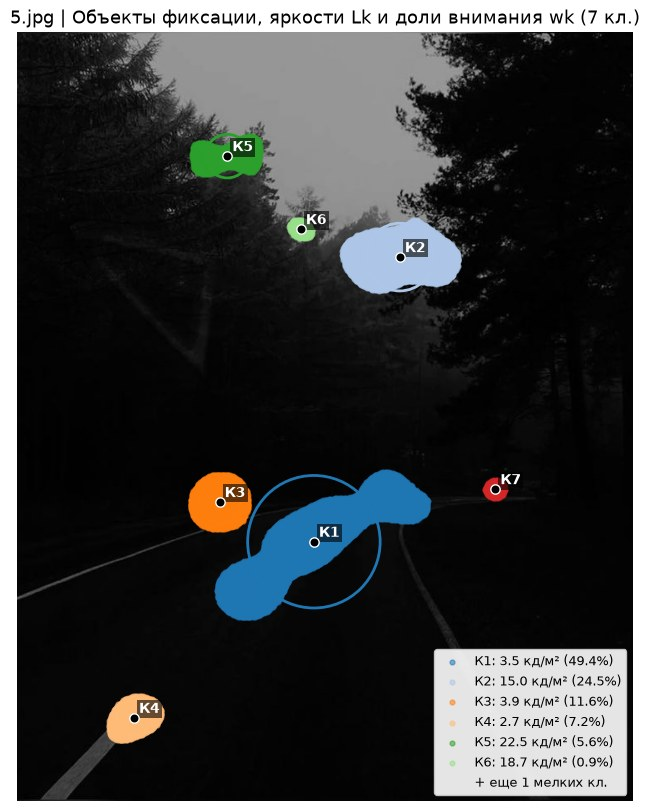

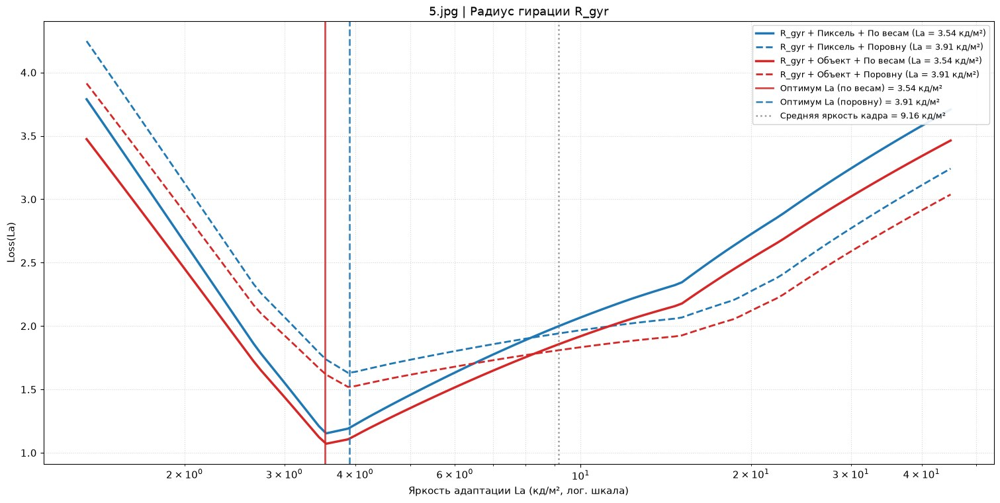

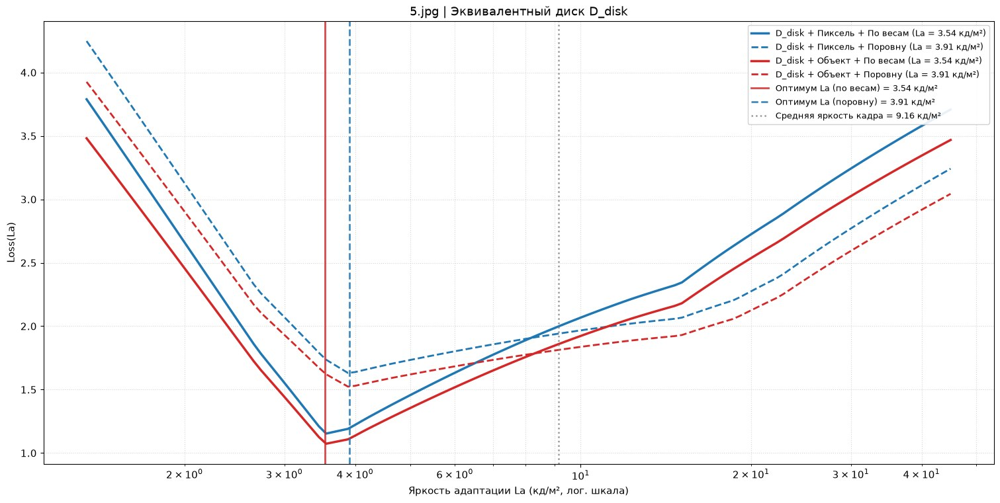

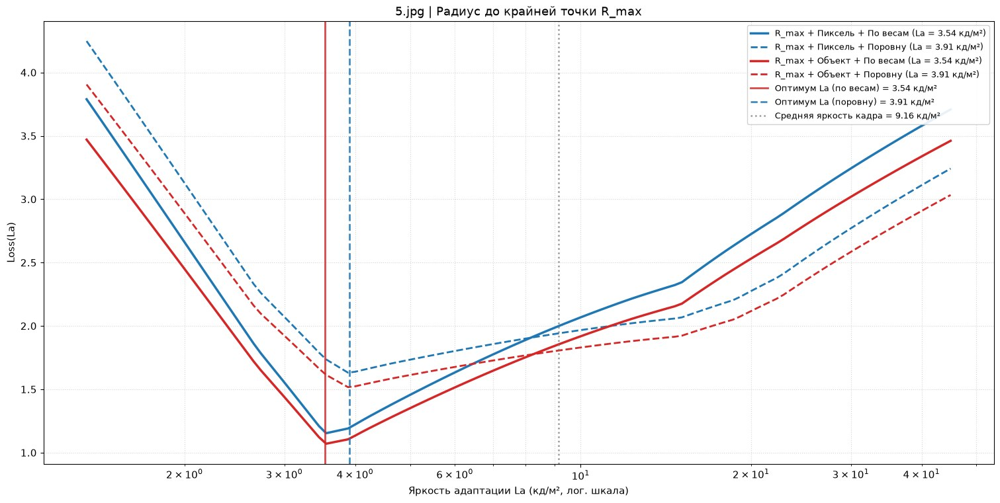

Результаты расчета La (5.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),3.91,1.6277
1,R_gyr,Пиксель,По весам,3.54,1.1510
2,R_gyr,Объект (R_gyr),Поровну (1/K),3.91,1.5164
3,R_gyr,Объект (R_gyr),По весам,3.54,1.0694
4,D_disk,Пиксель,Поровну (1/K),3.91,1.6277
5,D_disk,Пиксель,По весам,3.54,1.1510
6,D_disk,Объект (D_disk),Поровну (1/K),3.91,1.5202
7,D_disk,Объект (D_disk),По весам,3.54,1.0712
8,R_max,Пиксель,Поровну (1/K),3.91,1.6277
9,R_max,Пиксель,По весам,3.54,1.1510



Объекты фиксации (5.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,15504,"(354.2, 609.4)",3.54,49.37,56.35,127.12,232.76
1,К2,8408,"(457.0, 268.9)",15.00,24.52,41.50,64.93,112.59
2,К3,3740,"(241.5, 561.9)",3.89,11.58,27.68,39.19,57.43
3,К4,2540,"(139.1, 820.1)",2.69,7.17,22.81,33.40,55.88
4,К5,2744,"(250.6, 148.2)",22.50,5.56,23.71,41.85,68.38
5,К6,488,"(338.6, 235.5)",18.73,0.94,10.00,14.49,23.26
6,К7,432,"(571.2, 546.5)",3.91,0.85,9.41,13.34,19.73



Изображение: 6.jpg | Разрешение: 500x375 px
Средняя яркость кадра: 89.37 кд/м² | Медианная: 89.91 кд/м²

Яркости кластеров L_k (1 шт.): [80.38] кд/м²



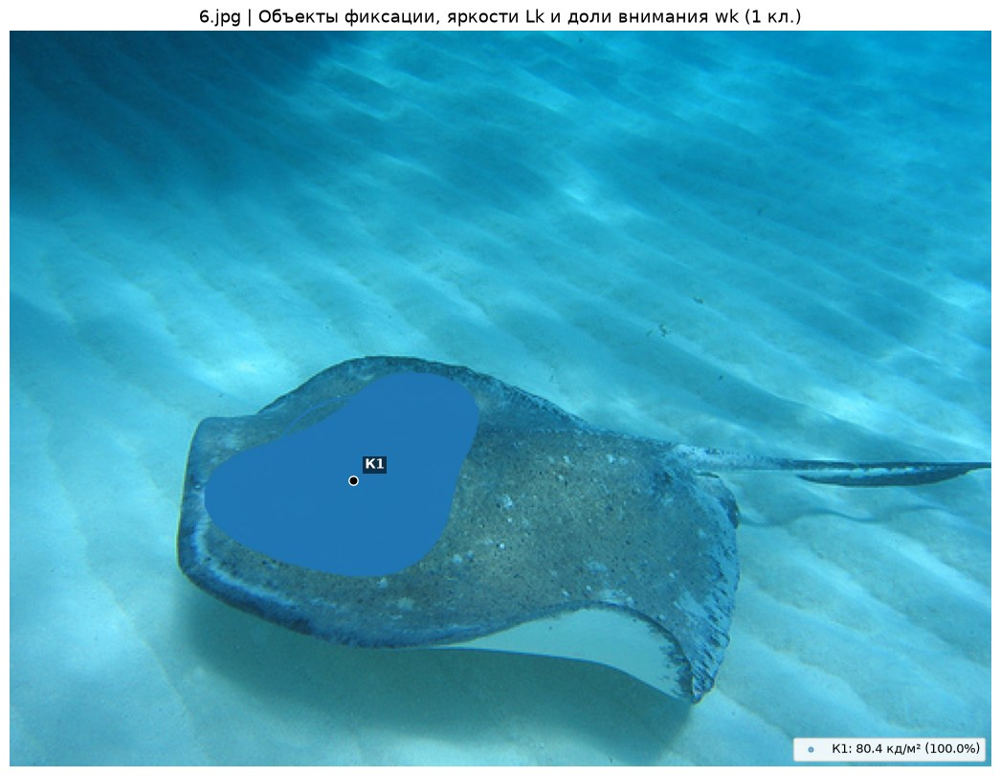

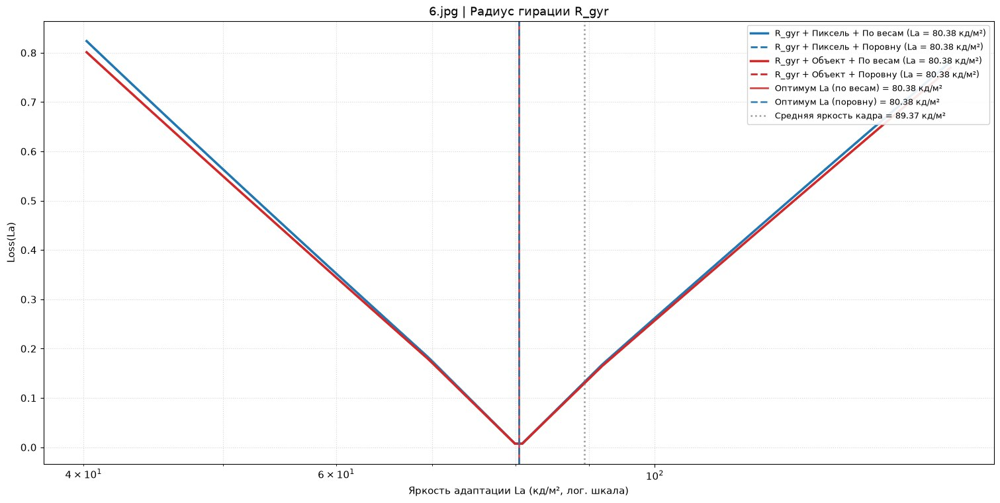

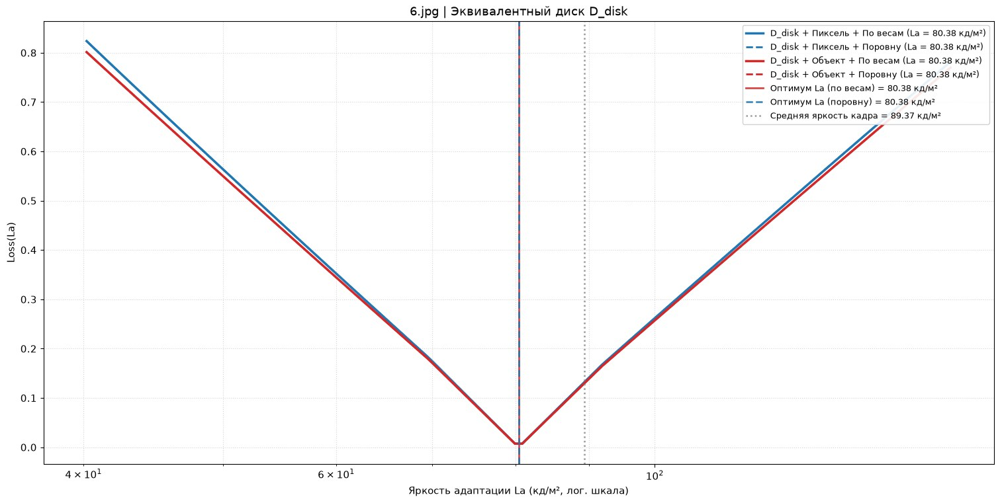

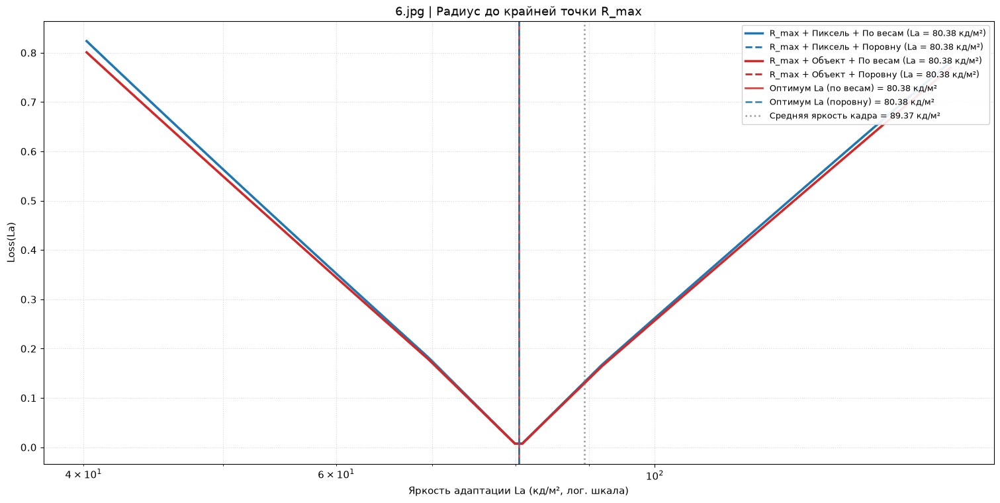

Результаты расчета La (6.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),80.38,0.0
1,R_gyr,Пиксель,По весам,80.38,0.0
2,R_gyr,Объект (R_gyr),Поровну (1/K),80.38,0.0
3,R_gyr,Объект (R_gyr),По весам,80.38,0.0
4,D_disk,Пиксель,Поровну (1/K),80.38,0.0
5,D_disk,Пиксель,По весам,80.38,0.0
6,D_disk,Объект (D_disk),Поровну (1/K),80.38,0.0
7,D_disk,Объект (D_disk),По весам,80.38,0.0
8,R_max,Пиксель,Поровну (1/K),80.38,0.0
9,R_max,Пиксель,По весам,80.38,0.0



Объекты фиксации (6.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,9375,"(174.5, 228.6)",80.38,100.0,64.5,99.09,178.82



Изображение: 7.jpg | Разрешение: 640x425 px
Средняя яркость кадра: 57.41 кд/м² | Медианная: 45.84 кд/м²

Яркости кластеров L_k (6 шт.): [83.17, 62.17, 69.99, 44.93, 60.54, 50.72] кд/м²



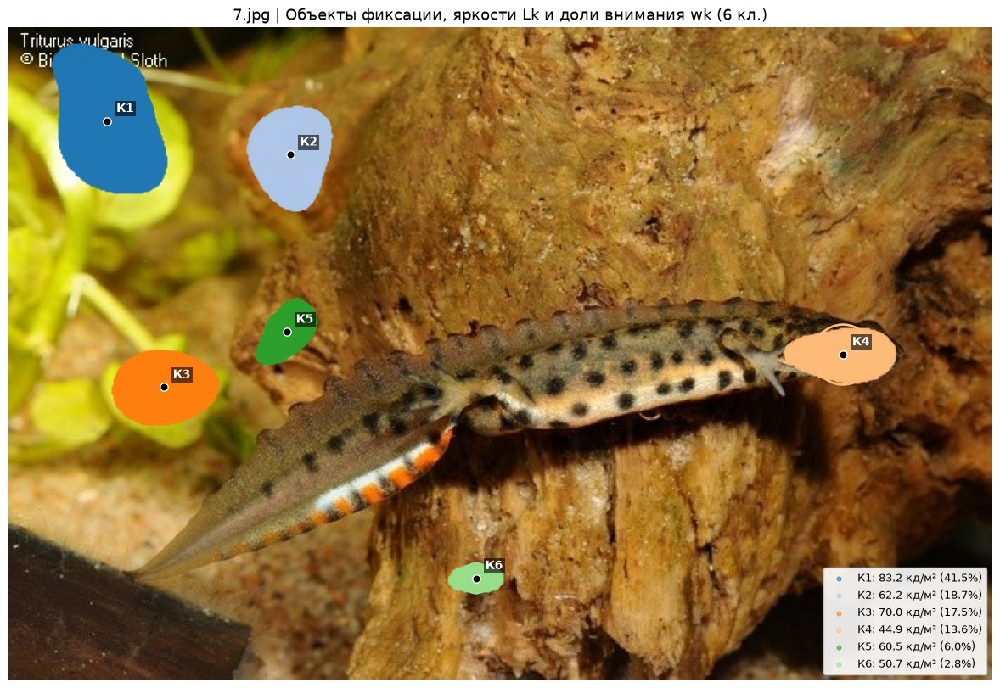

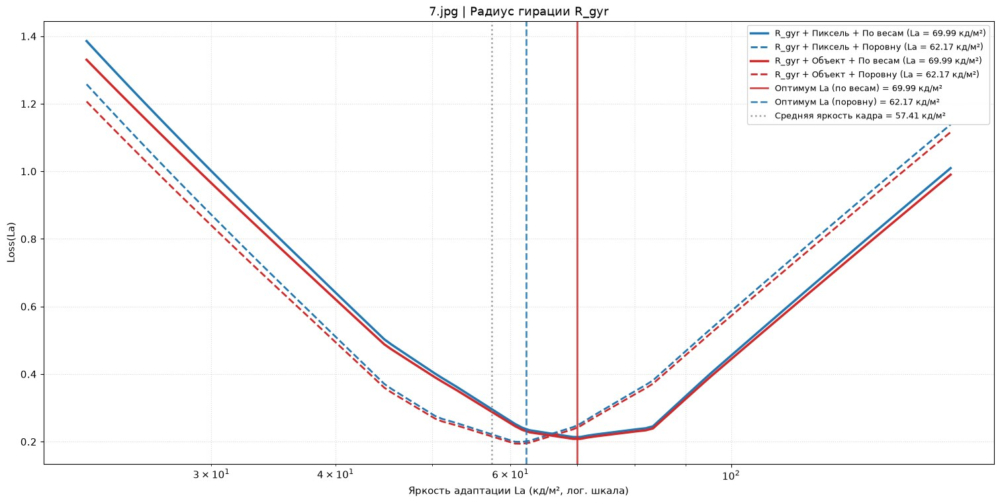

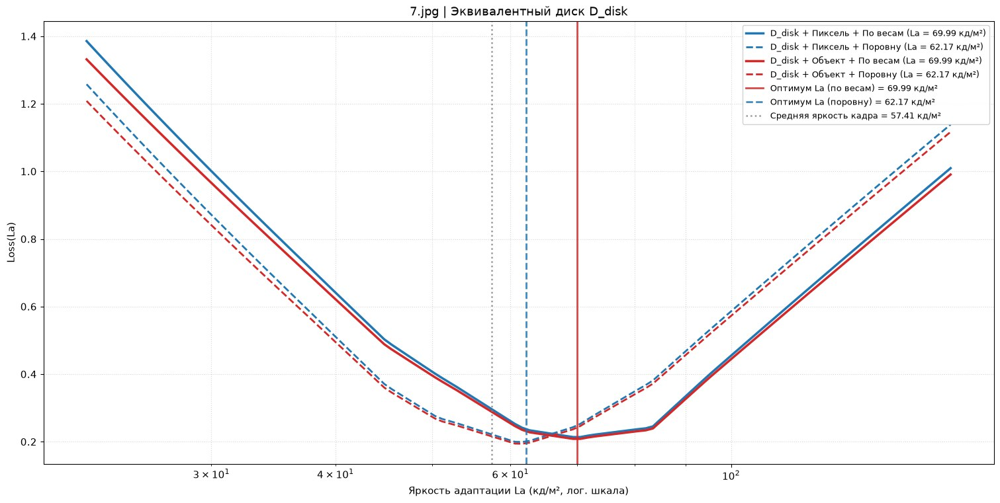

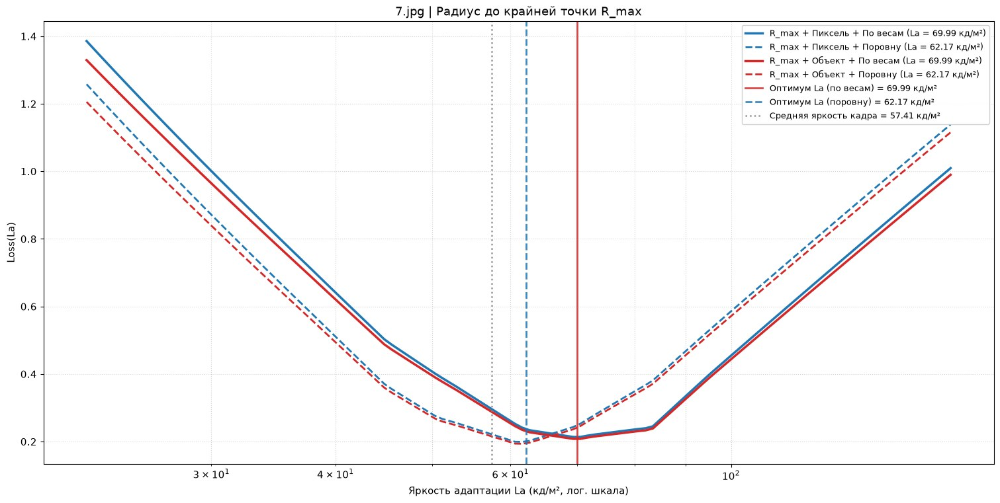

Результаты расчета La (7.jpg):


,Метод радиуса,Стимул,Веса,La (кд/м2),Loss(La)
0,R_gyr,Пиксель,Поровну (1/K),62.17,0.1991
1,R_gyr,Пиксель,По весам,69.99,0.2119
2,R_gyr,Объект (R_gyr),Поровну (1/K),62.17,0.1937
3,R_gyr,Объект (R_gyr),По весам,69.99,0.2065
4,D_disk,Пиксель,Поровну (1/K),62.17,0.1991
5,D_disk,Пиксель,По весам,69.99,0.2119
6,D_disk,Объект (D_disk),Поровну (1/K),62.17,0.1939
7,D_disk,Объект (D_disk),По весам,69.99,0.2066
8,R_max,Пиксель,Поровну (1/K),62.17,0.1991
9,R_max,Пиксель,По весам,69.99,0.2119



Объекты фиксации (7.jpg):


,Объект,Площадь (px),"Центр (x, y)",Яркость Lk (кд/м2),Вес (%),D_disk (мрад),D_gyr (мрад),D_max (мрад)
0,К1,5179,"(63.7, 60.9)",83.17,41.46,37.45,56.78,101.36
1,К2,2657,"(183.2, 82.7)",62.17,18.68,26.83,38.93,66.06
2,К3,2488,"(100.5, 234.1)",69.99,17.47,25.96,37.97,64.29
3,К4,1830,"(542.6, 212.9)",44.93,13.56,22.26,36.06,69.50
4,К5,986,"(180.6, 198.1)",60.54,6.00,16.34,25.47,47.59
5,К6,460,"(303.8, 358.6)",50.72,2.82,11.16,17.78,31.39


In [12]:
OLD_JND_IMAGES = sorted([
    p for p in (BASE_DIR / 'examples_old_jnd').iterdir()
    if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
])

print(f'Изображений в examples_old_jnd/: {len(OLD_JND_IMAGES)}')
for img_path in OLD_JND_IMAGES:
    run_experiment_4(img_path)